# Setting up

In [1]:
# Data handlers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Models
from scipy.optimize import minimize_scalar, curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
import xgboost
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import tensorflow as tf


# Preprocessors
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluators
from sklearn.metrics import r2_score, mean_absolute_error as mae, mean_squared_error as mse


In [2]:
df = pd.read_csv('cleaned data.csv')
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [3]:
X = df.drop(columns = 'Output')
Y = df['Output']

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Plotting function

In [5]:
var1 = df['variable 1'].unique()
var2 = df['variable 2'].unique()


def plot2d_var1const(model):

    fig,ax = plt.subplots(5,5, figsize = (20,20))

    for i in range(5):
        for j in range(5):
            temp = df[df['variable 1'] == var1[5*i+j]]
            ax[i,j].plot(temp['variable 2'], temp['Output'], marker = 'o')
            ax[i,j].plot(temp['variable 2'], temp[model], marker = 'o')
            ax[i,j].set_title('variable 1 = '+str(var1[5*i+j]))

    plt.show()


def plot2d_var2const(model):

    fig,ax = plt.subplots(5,5, figsize = (20,20))

    for i in range(5):
        for j in range(5):
            temp = df[df['variable 2'] == var1[5*i+j]]
            ax[i,j].plot(temp['variable 1'], temp['Output'], marker = 'o')
            ax[i,j].plot(temp['variable 1'], temp[model], marker = 'o')
            ax[i,j].set_title('variable 2 = '+str(var2[5*i+j]))

    plt.show()

def plot3d(model):
    fig = plt.figure(figsize = (10,10))
    ax = fig.add_subplot(projection = '3d')
    ax.scatter(df['variable 1'], df['variable 2'], df['Output'], marker = 'o', color = 'blue', alpha = 0.25)
    ax.scatter(df['variable 1'], df['variable 2'], df[model], marker = 'o', color = 'orange')
    ax.set_xlabel('Var 1')
    ax.set_ylabel('Var 2')
    ax.set_zlabel('Output')
    plt.show()

# Custom curve fit

In [7]:
def model_eq(X,k1,k2,k3,k4,k5,k6,k7):
    y,x = X
    return k2*y*np.exp(-k1*x) + k3*np.exp(-k1*x) - k4*x*y + k5*x + k6*y + k7

p0 = [0.1, 1.0, 1.0, 0., 0., 0., 0.]
lower_bounds = [0.001, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf]
upper_bounds = [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf]
bounds = (lower_bounds, upper_bounds)

popt,pcov = curve_fit(model_eq,X.T,Y,p0 = p0, bounds = bounds)

popt

array([  1.39160846, -21.66588409,  16.59125191,  -3.32934745,
       -67.99564237, -13.30577208, 204.88515164])

In [9]:
df['custom'] = model_eq(X.T, *popt)

print(mse(Y, df['custom']))

113.79039603311766


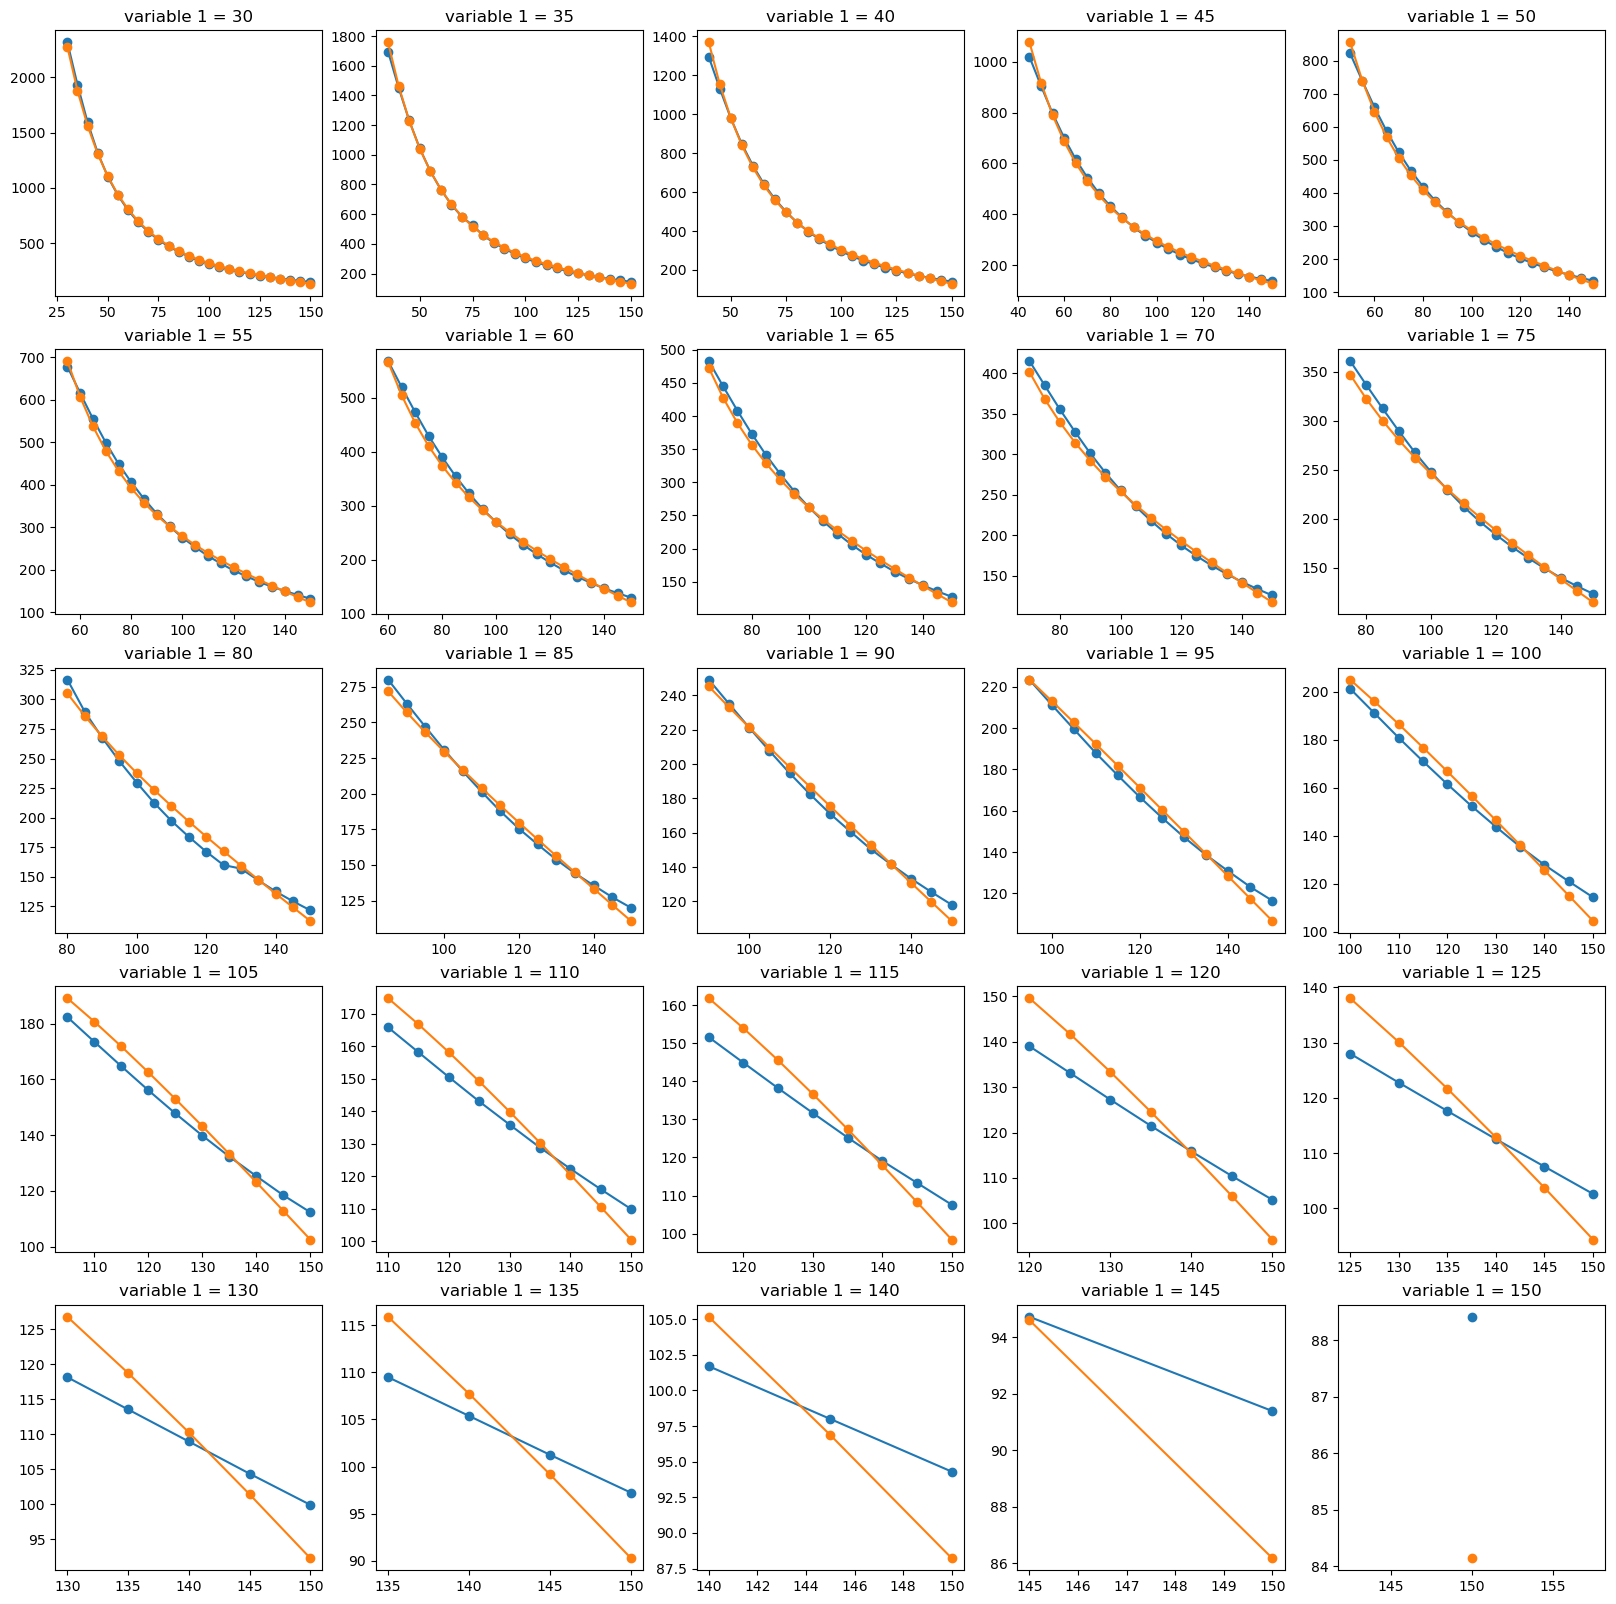

In [10]:
plot2d_var1const('custom')

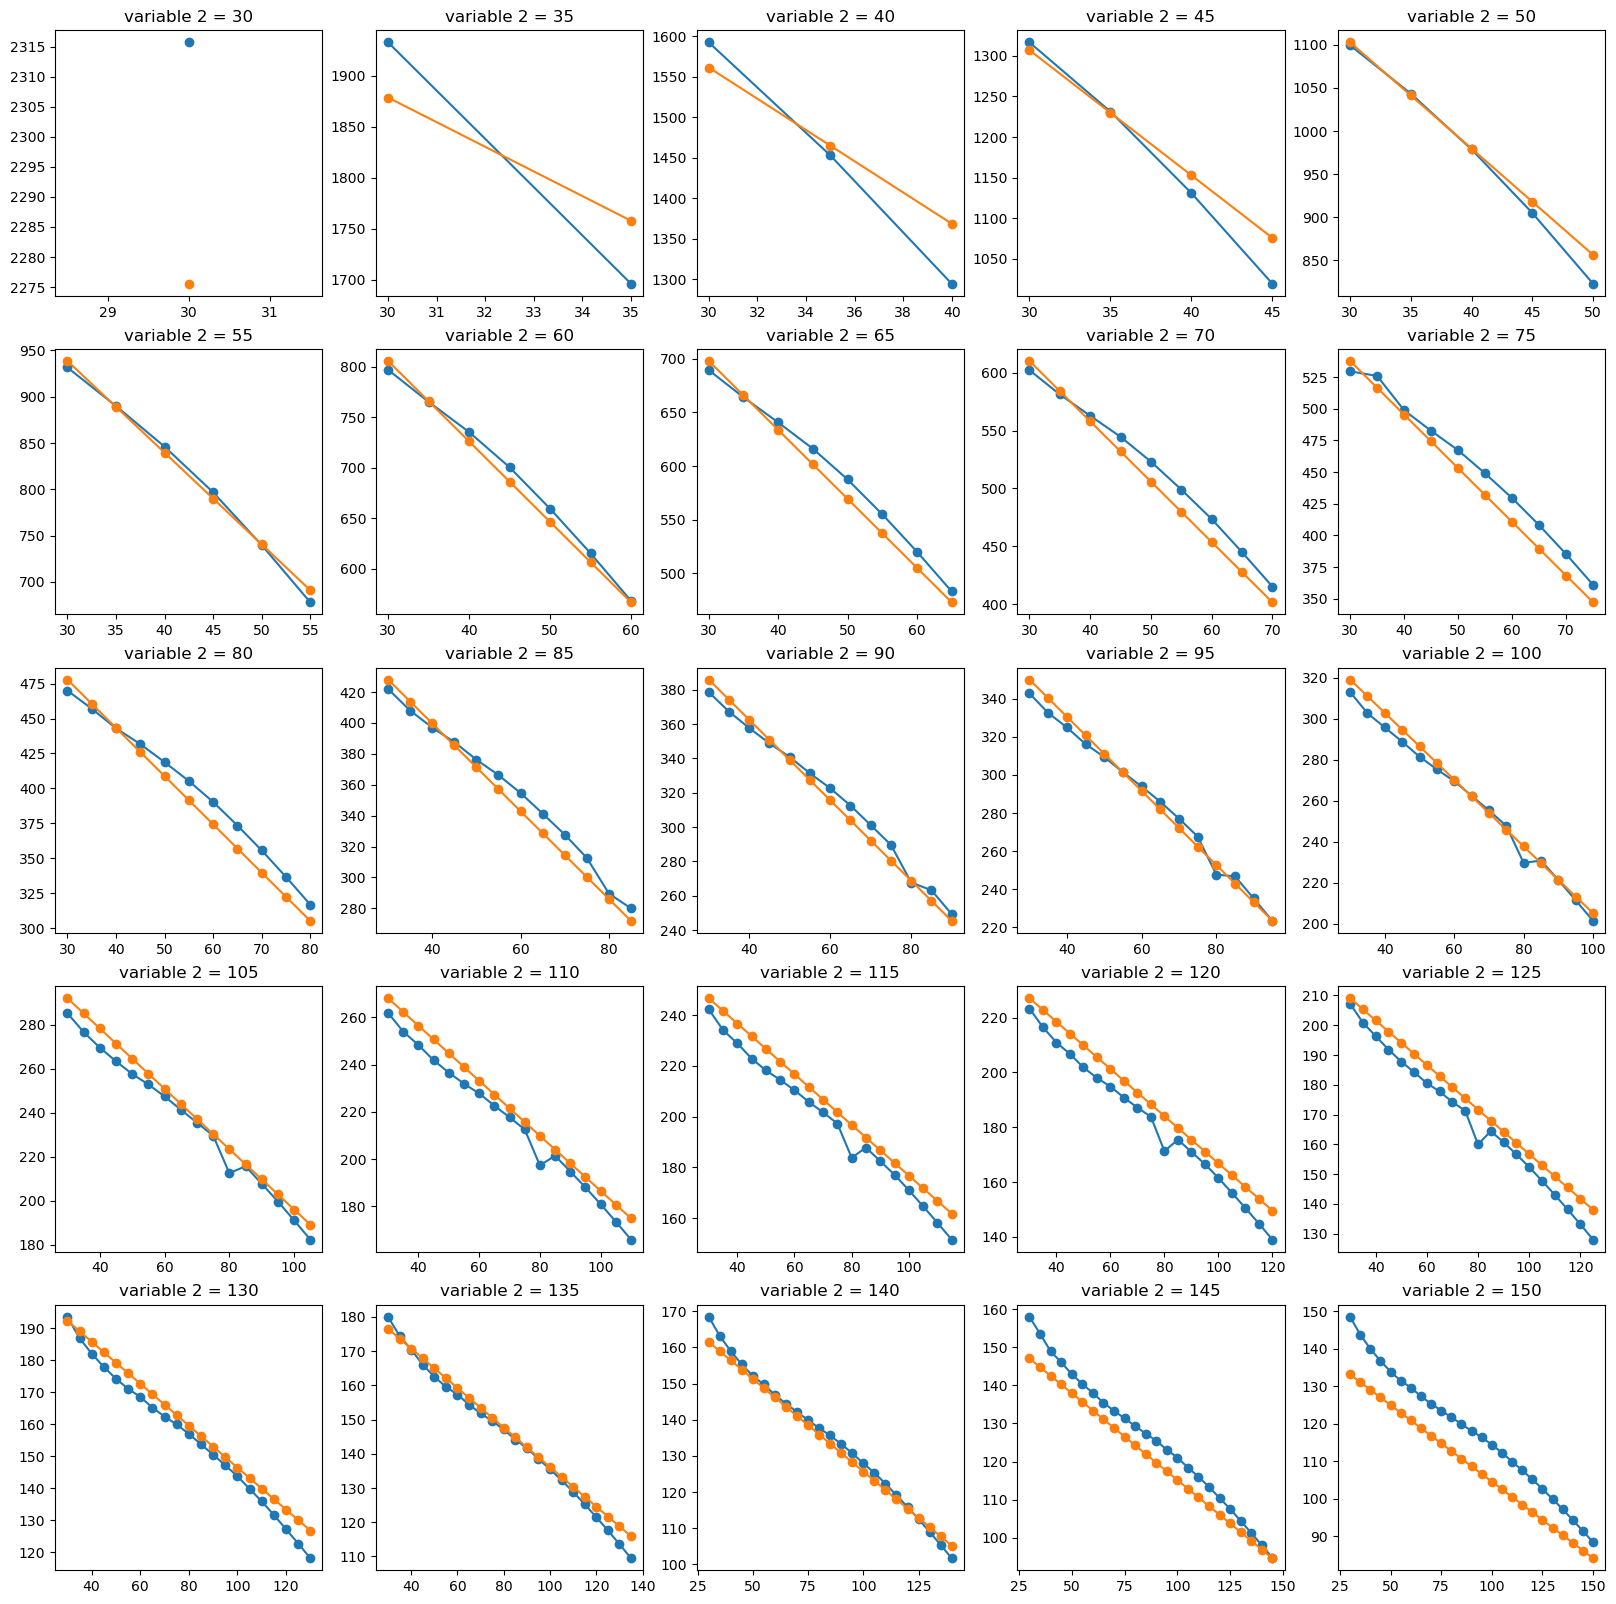

In [11]:
plot2d_var2const('custom')

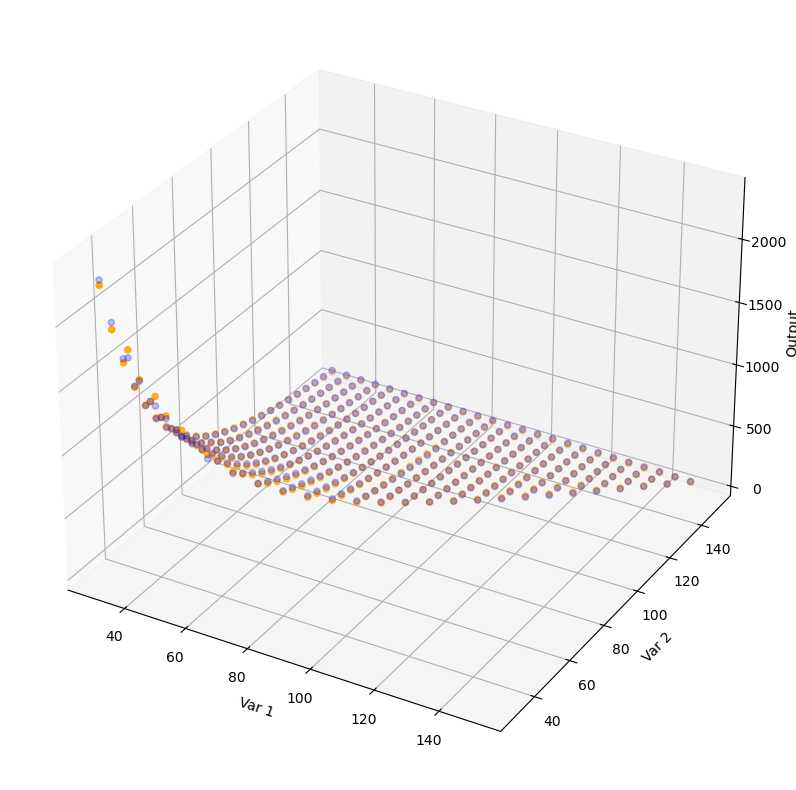

In [12]:
plot3d('custom')

# Linear Regression

In [13]:
LinReg = LinearRegression()
LinReg.fit(X,Y)
df['Linreg'] = LinReg.predict(X)
print(mse(Y, df['Linreg']))

26034.305095744785


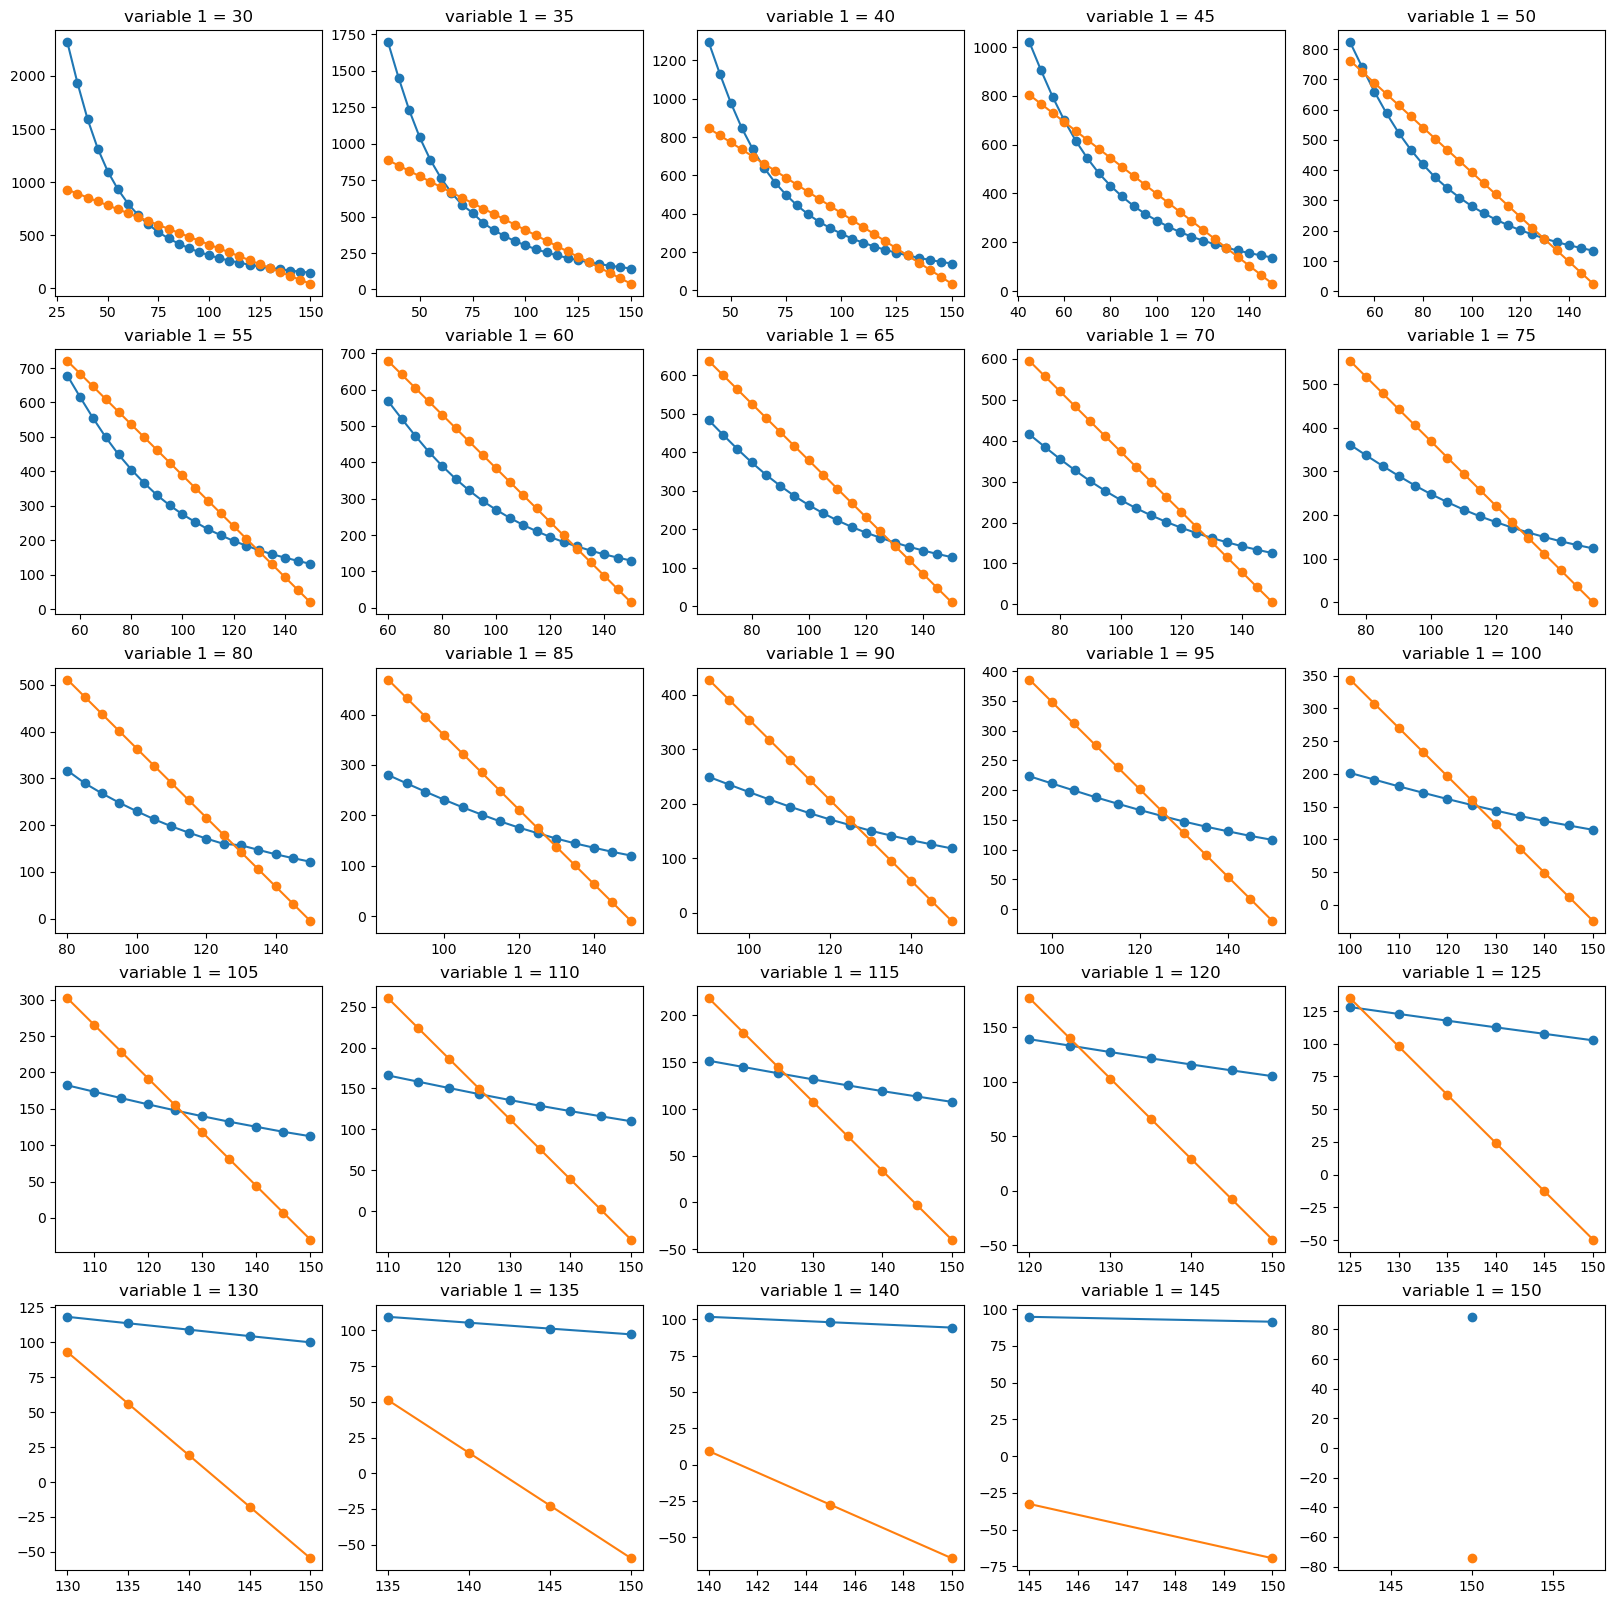

In [14]:
plot2d_var1const('Linreg')

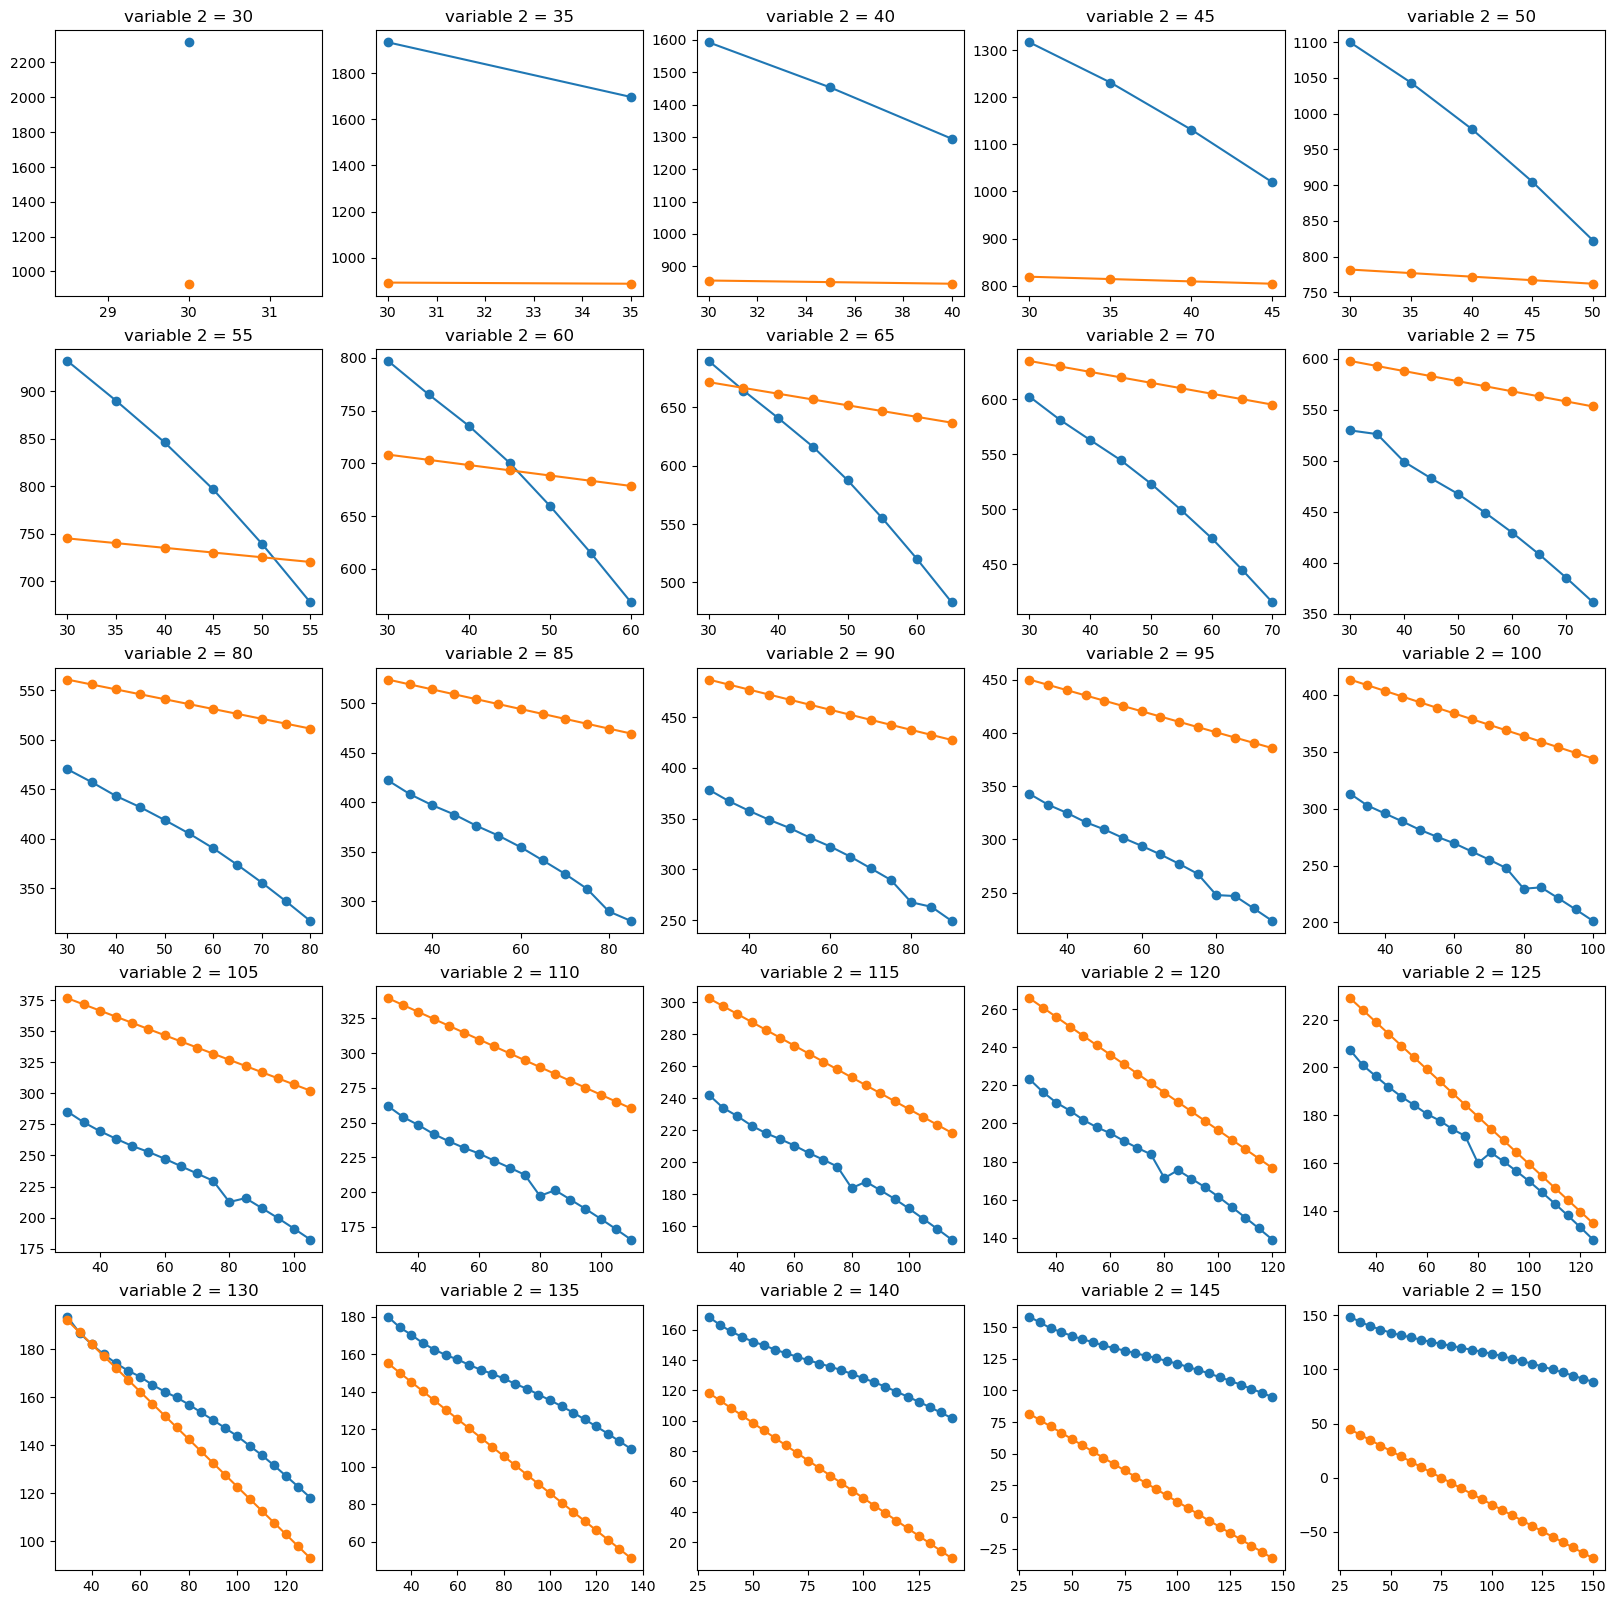

In [15]:
plot2d_var2const('Linreg')

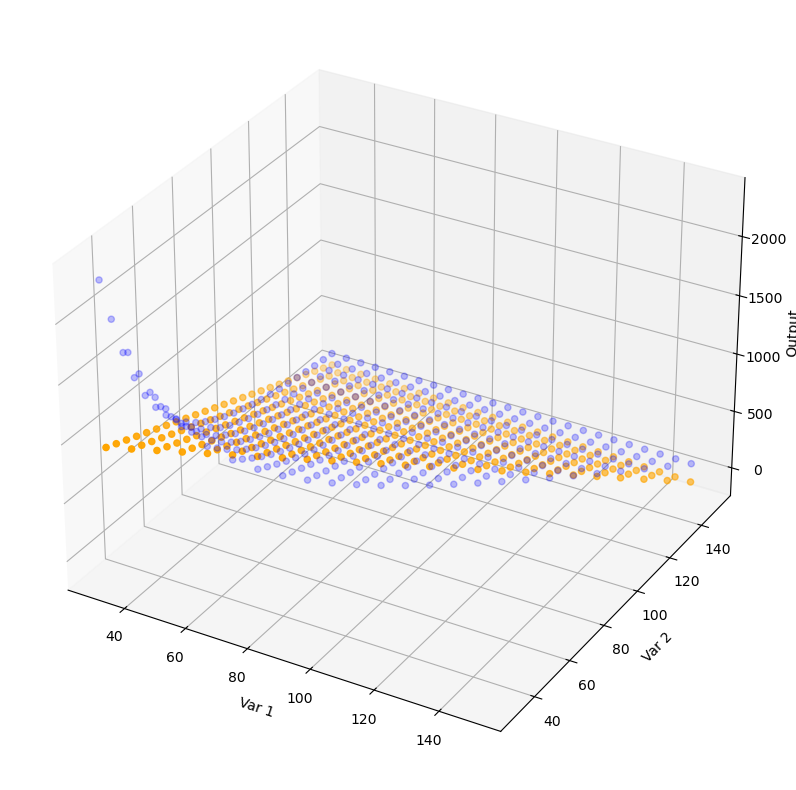

In [16]:
plot3d('Linreg')

# Decision Tree Regressor

In [17]:
DTReg = DecisionTreeRegressor(random_state = 0, max_depth = 4, min_samples_split = 2)
DTReg.fit(X,Y)
df['DTReg'] = DTReg.predict(X)
print(mse(Y, df['DTReg']))

1649.0956632380858


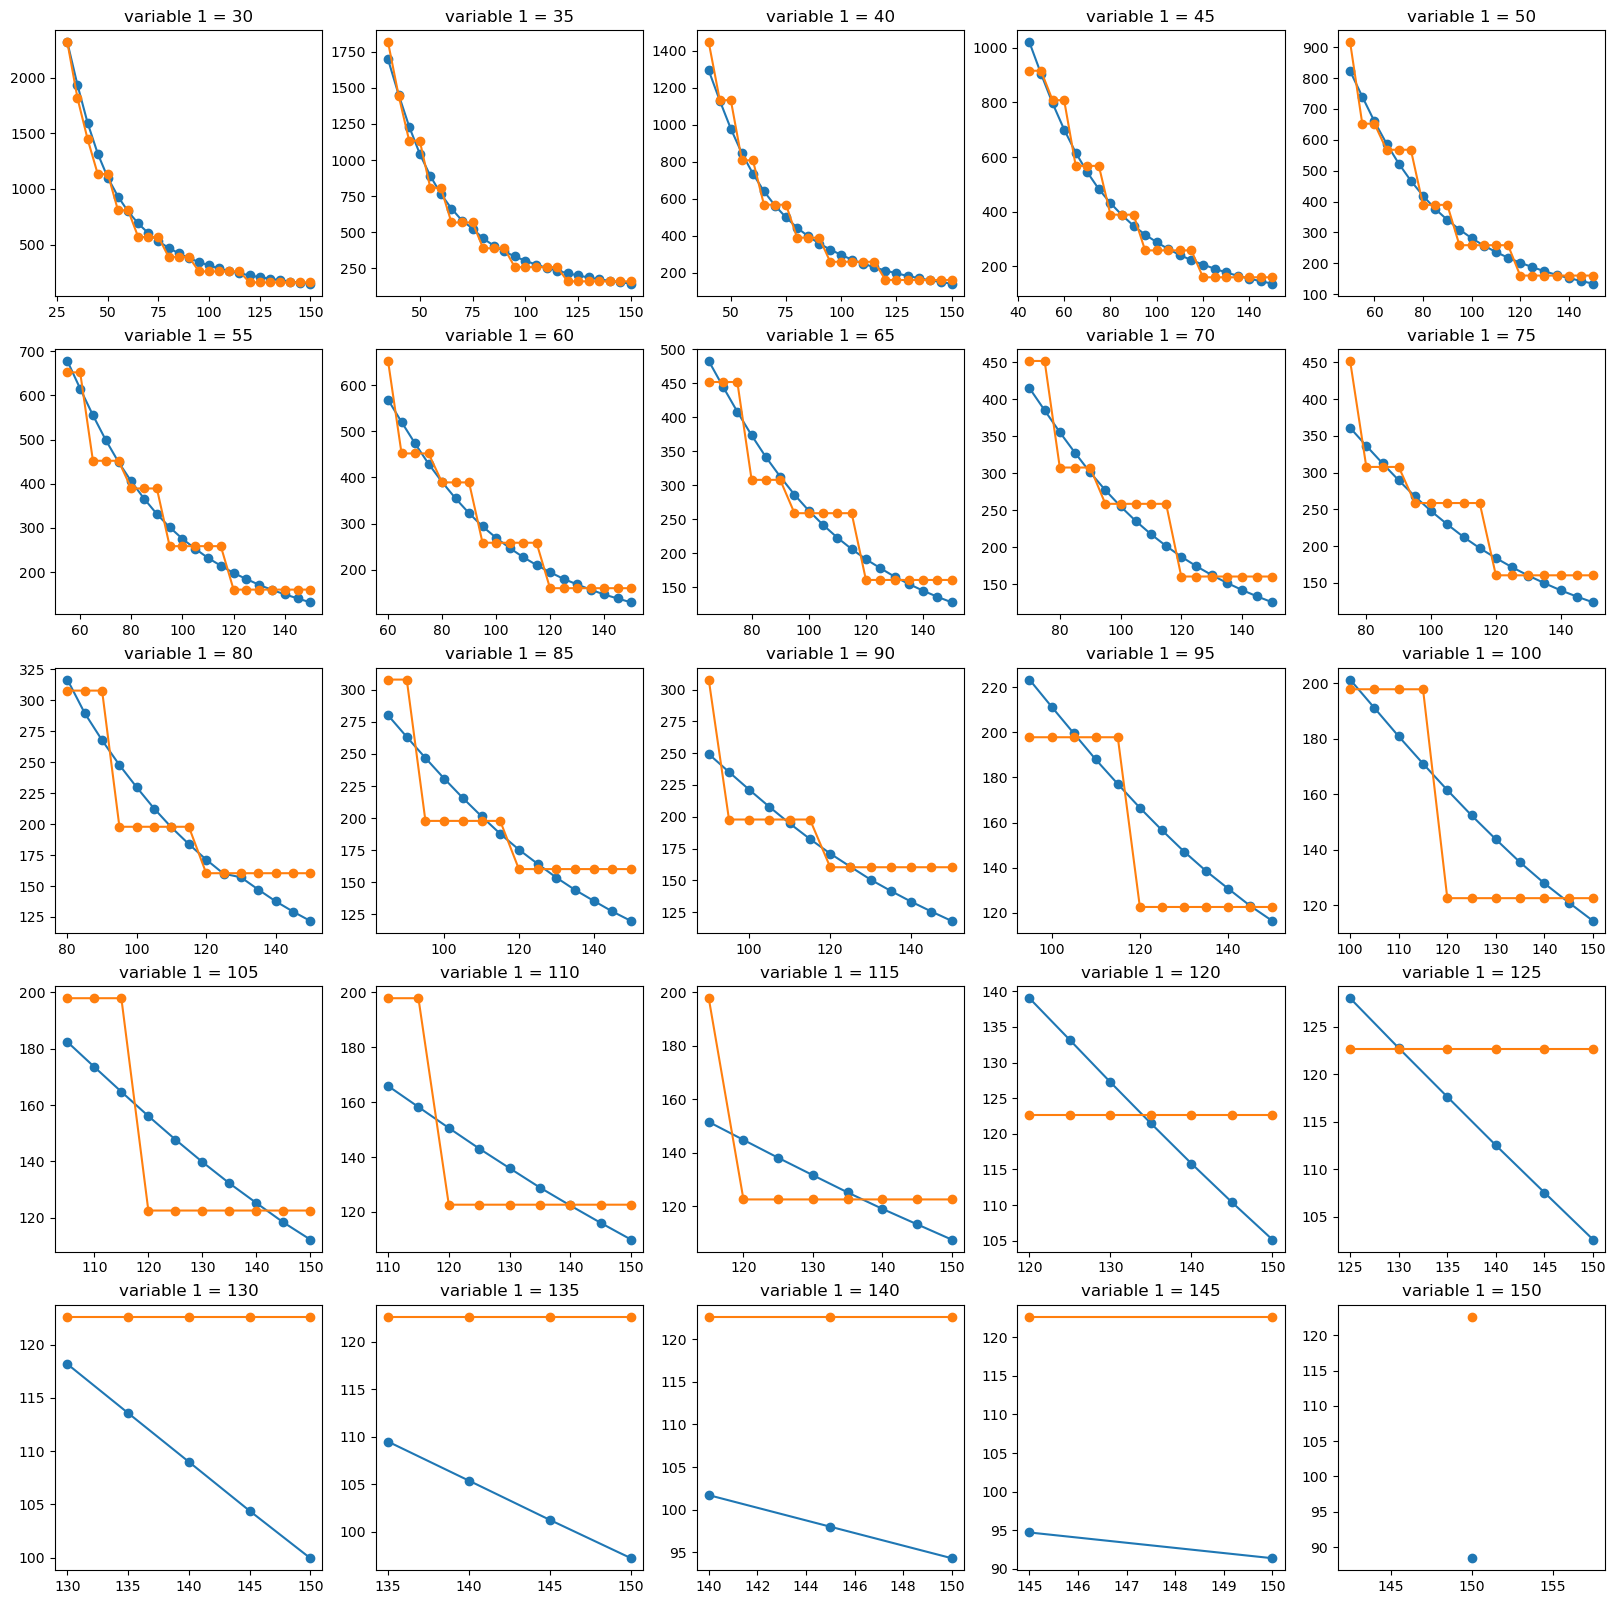

In [18]:
plot2d_var1const('DTReg')

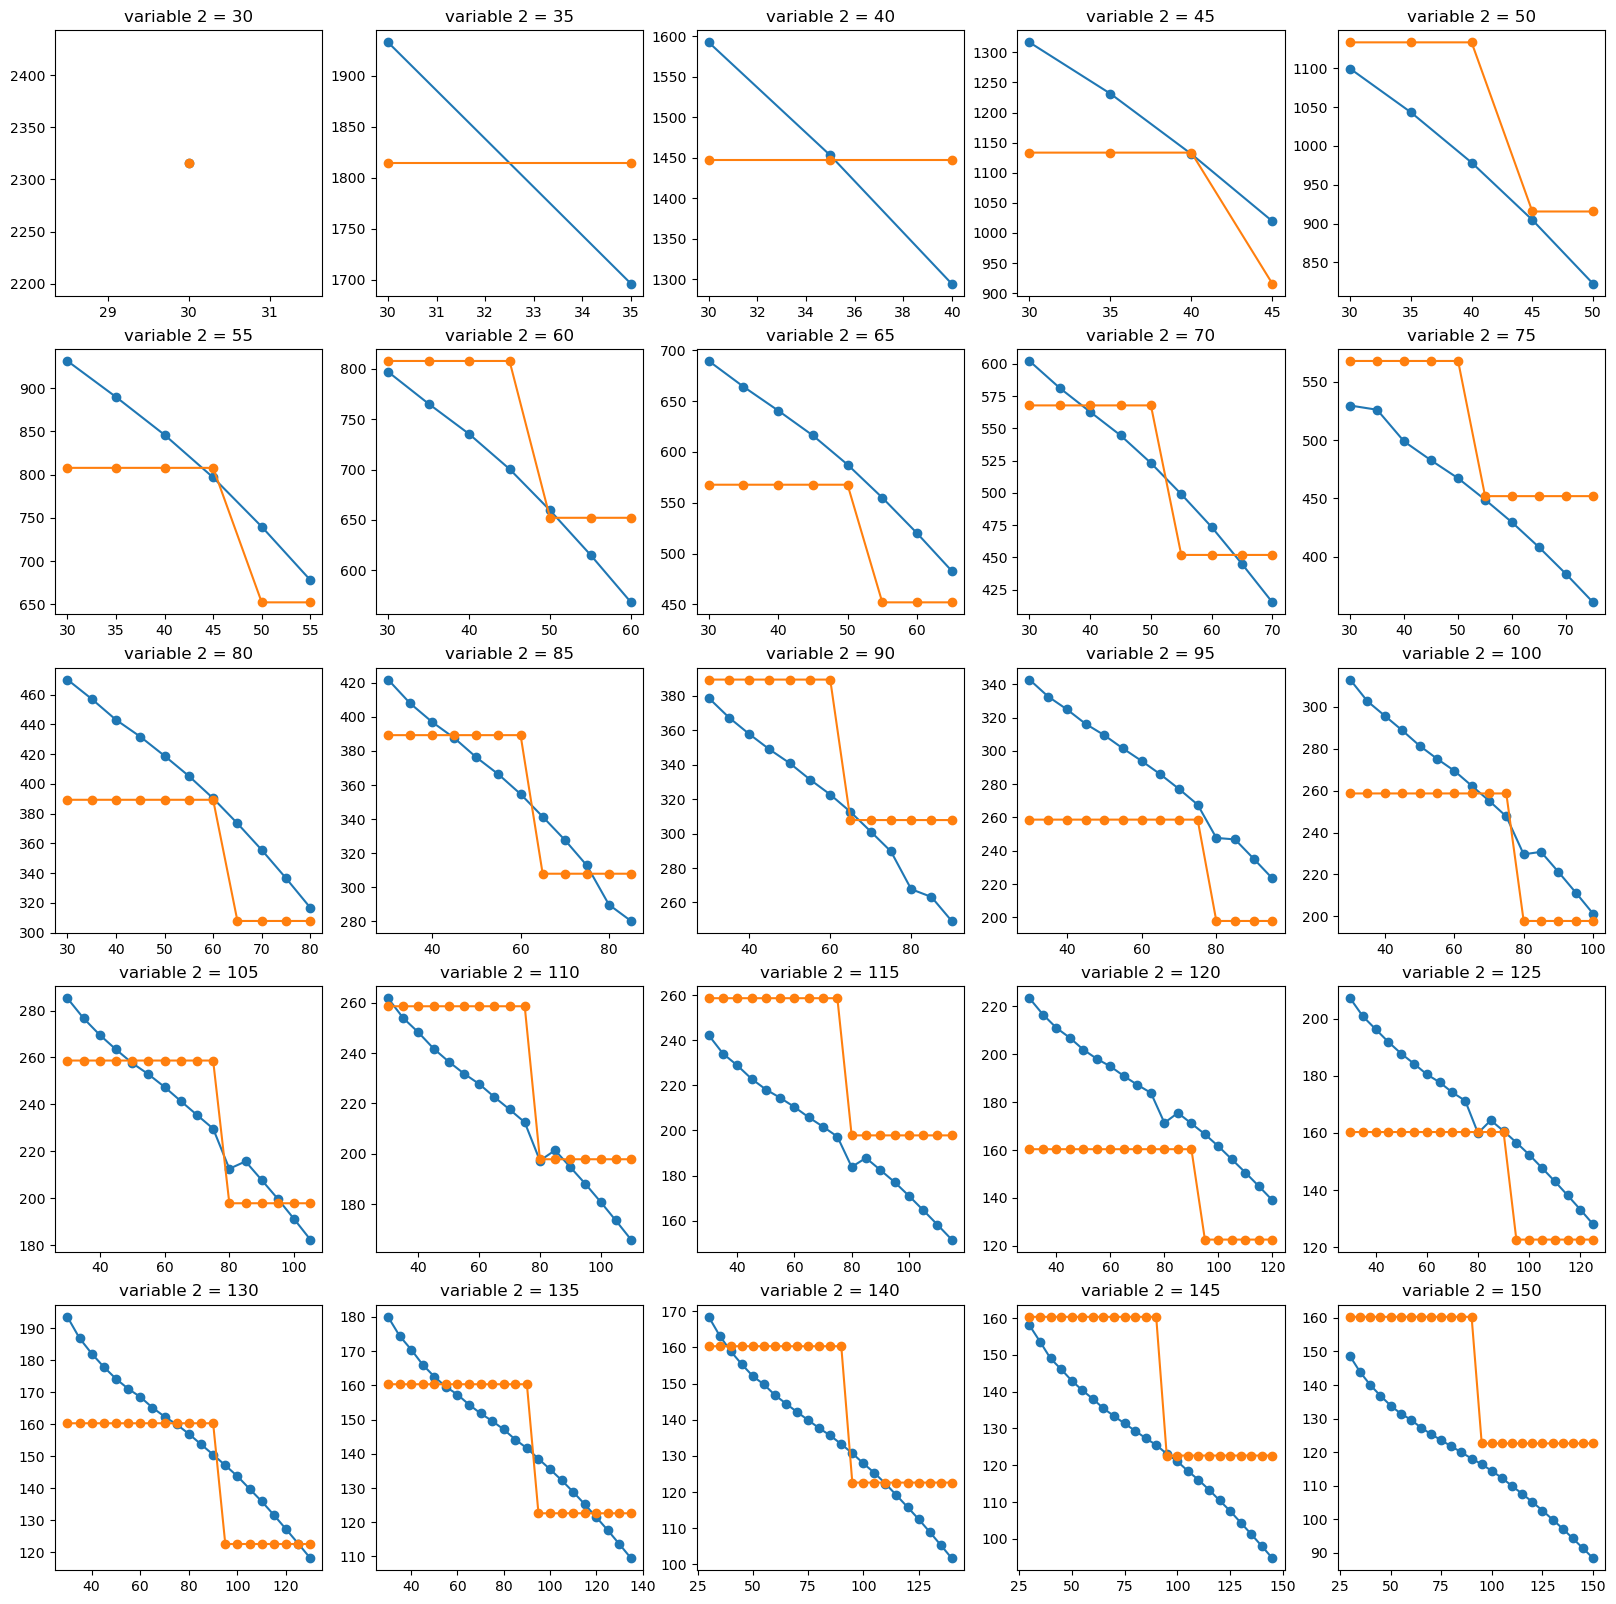

In [19]:
plot2d_var2const('DTReg')

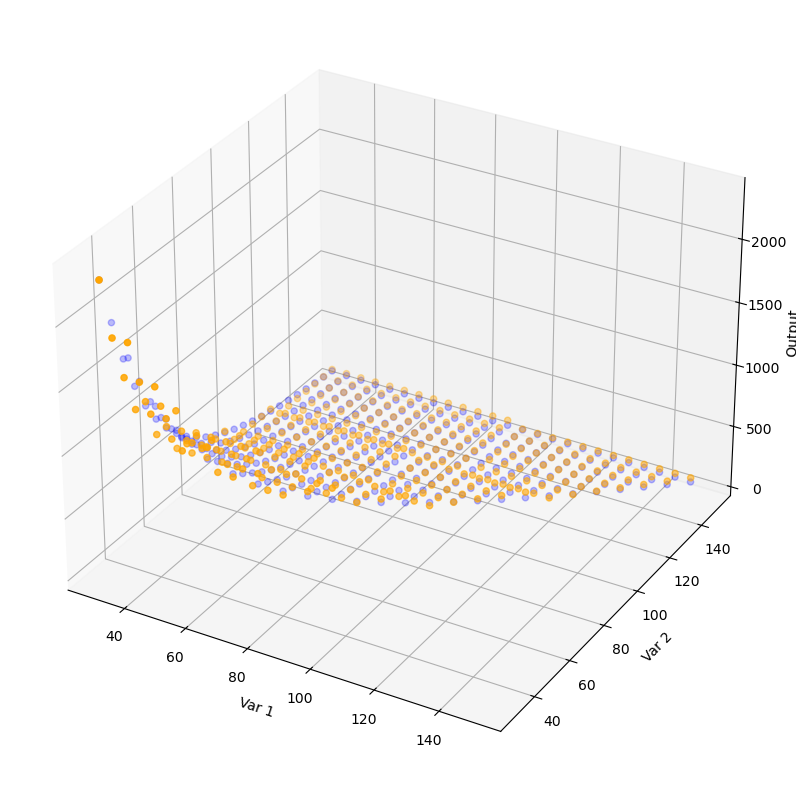

In [20]:
plot3d('DTReg')

# Random Forest Regressor

In [21]:
RFReg = RandomForestRegressor(n_estimators = 10, random_state = 0, oob_score = True)
RFReg.fit(X,Y)
df['RFReg'] = RFReg.predict(X)
print(mse(Y, df['RFReg']), '\n',
      RFReg.oob_score_)

154.9473124594151 
 0.9703884681403109


c:\Users\rajee\miniconda3\envs\mlenv\lib\site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


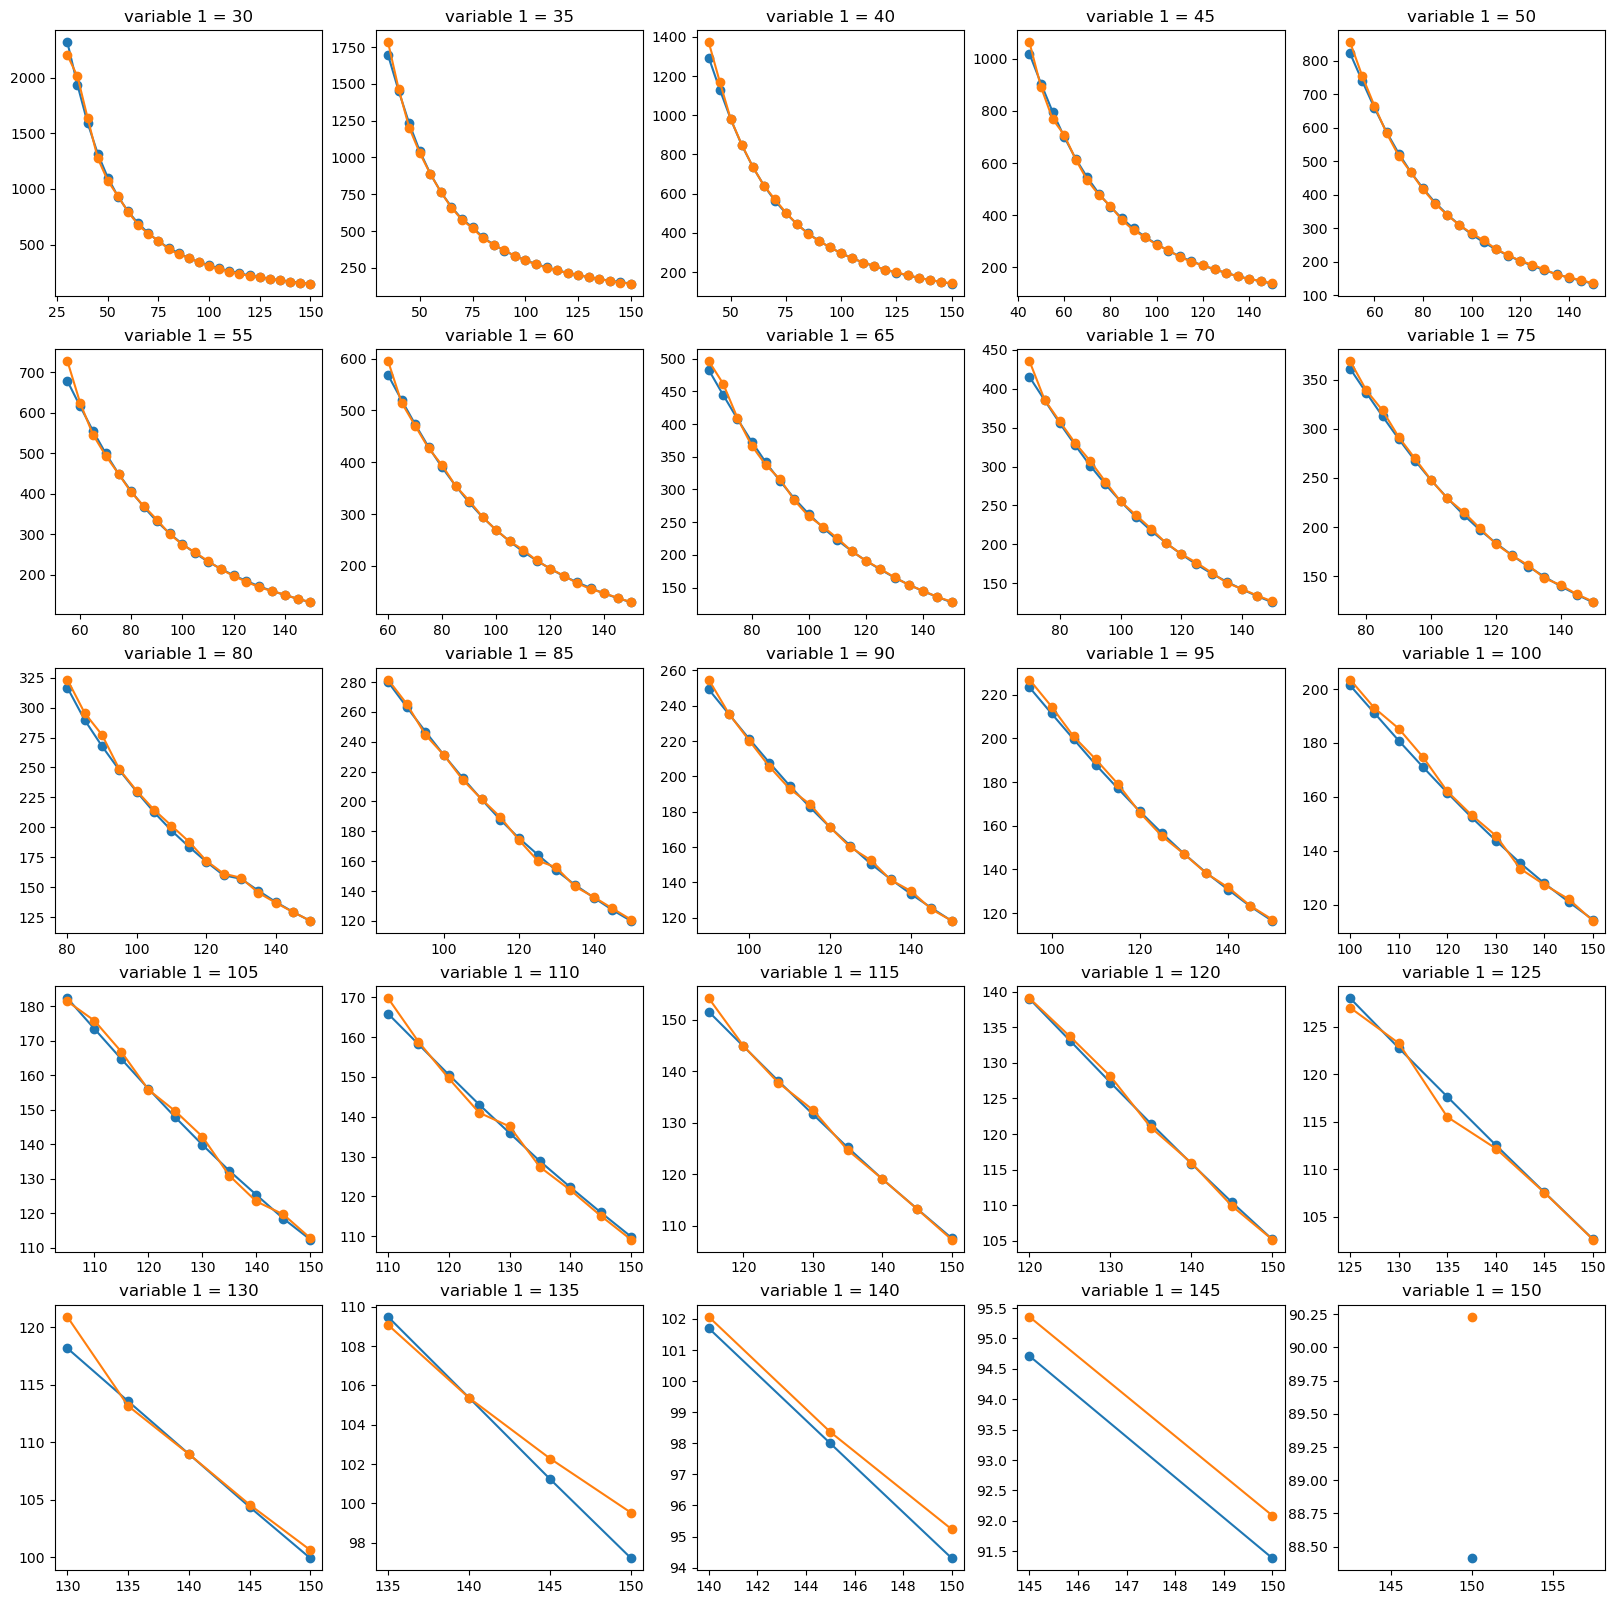

In [22]:
plot2d_var1const('RFReg')

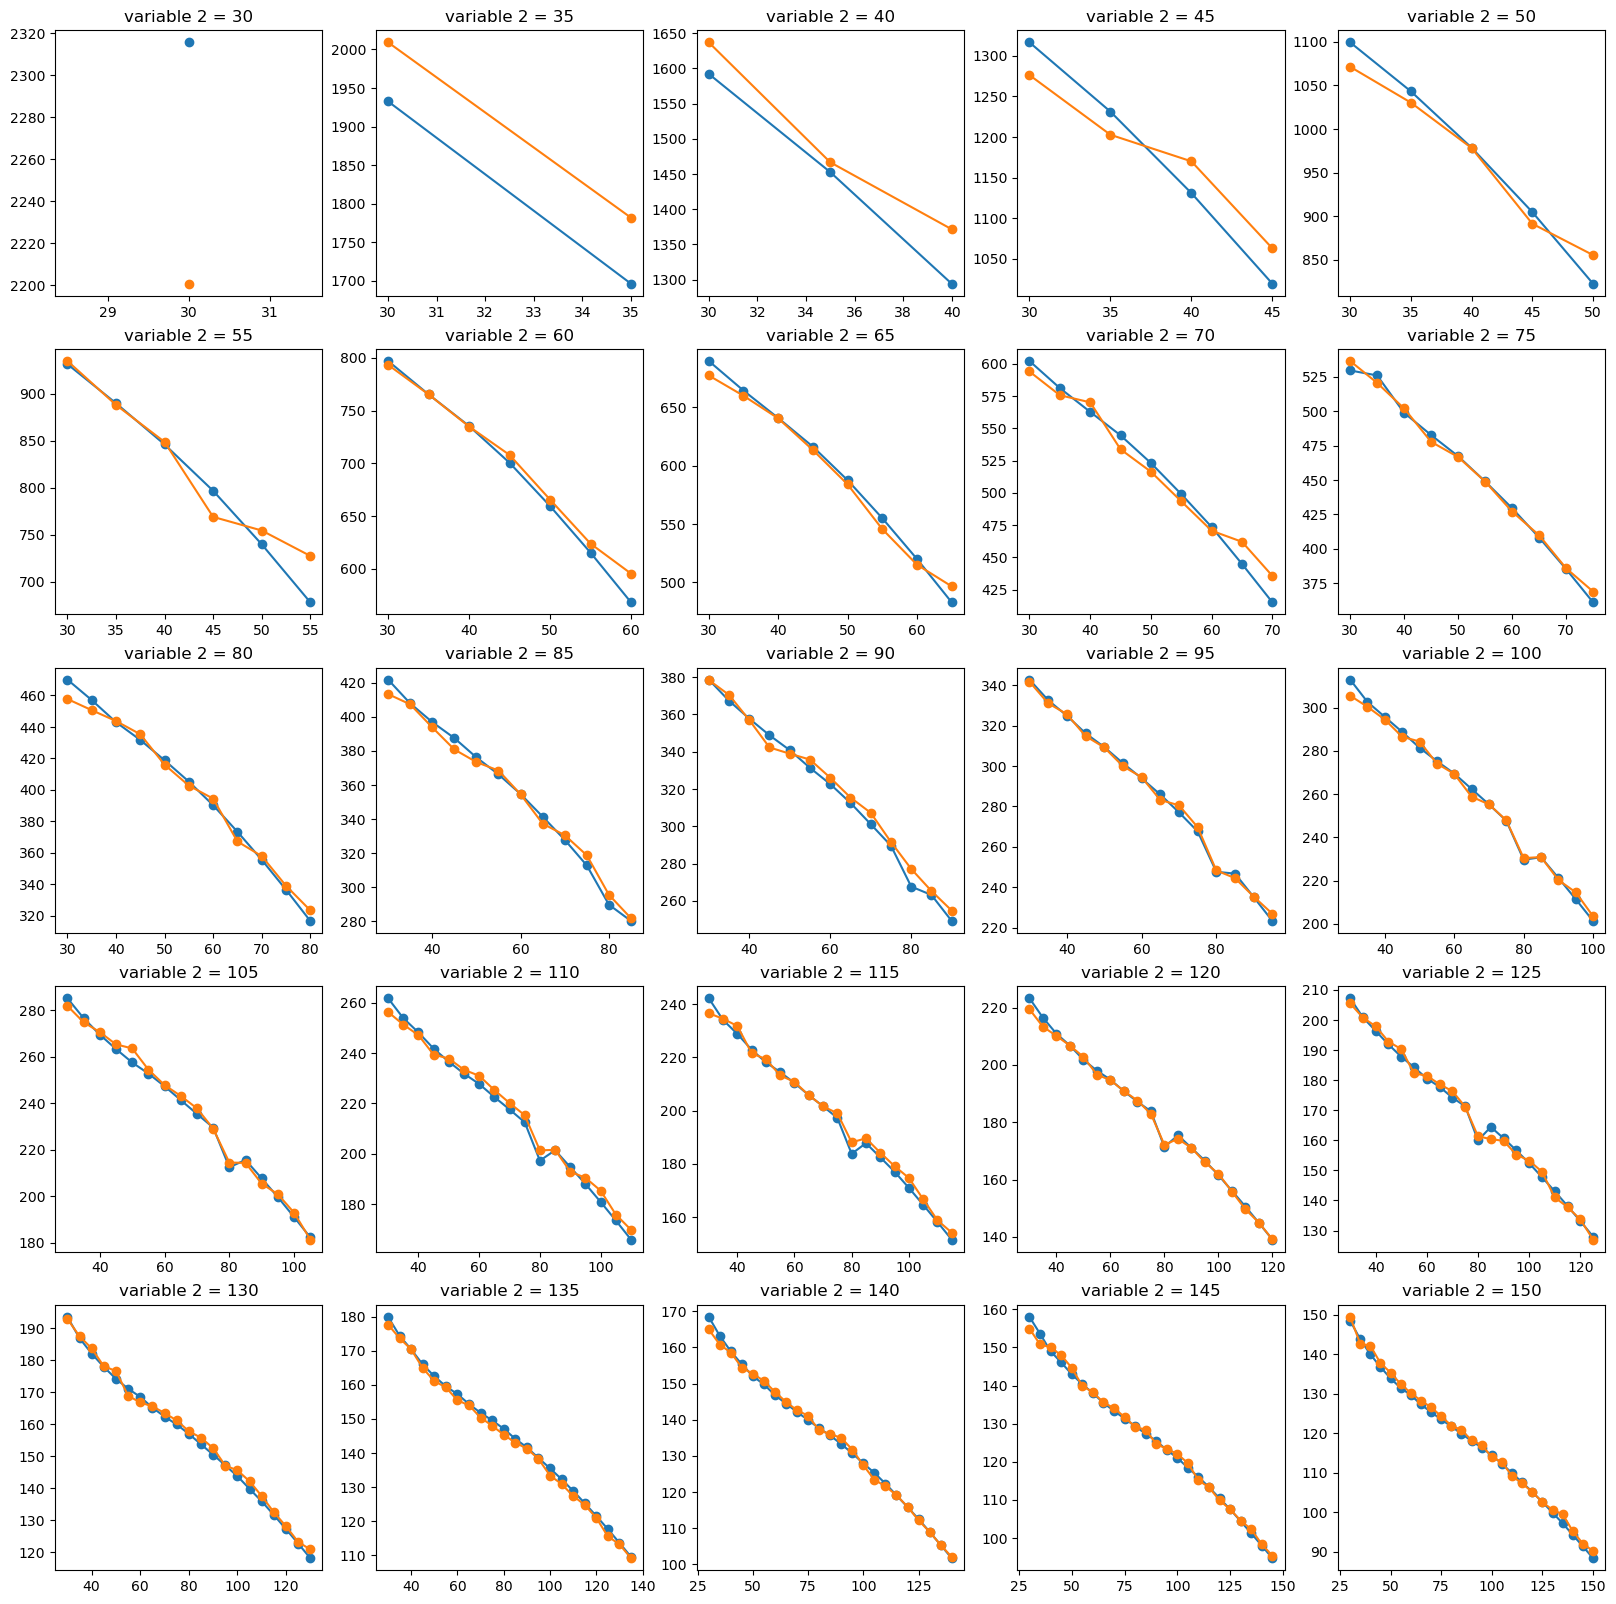

In [23]:
plot2d_var2const('RFReg')

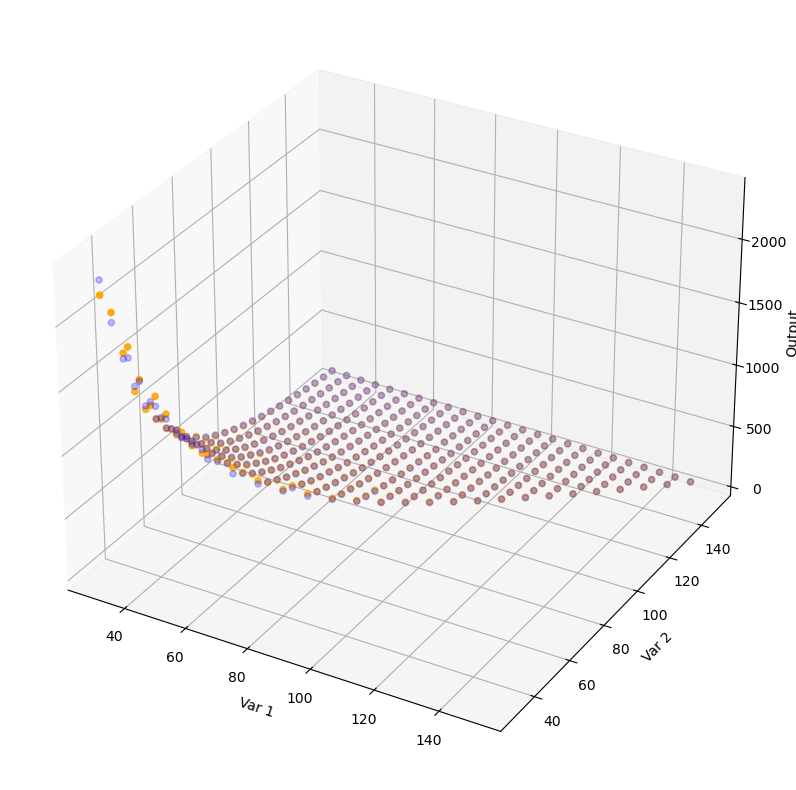

In [24]:
plot3d('RFReg')

# Gradient Boosting Regressor

In [25]:
GBR = GradientBoostingRegressor(loss = 'squared_error',
                                learning_rate = 0.1,
                                n_estimators = 40,
                                max_depth = 3,
                                random_state = 0)

GBR.fit(X,Y)
df['GBR'] = GBR.predict(X)
print(mse(Y, df['GBR']))

92.55233764248817


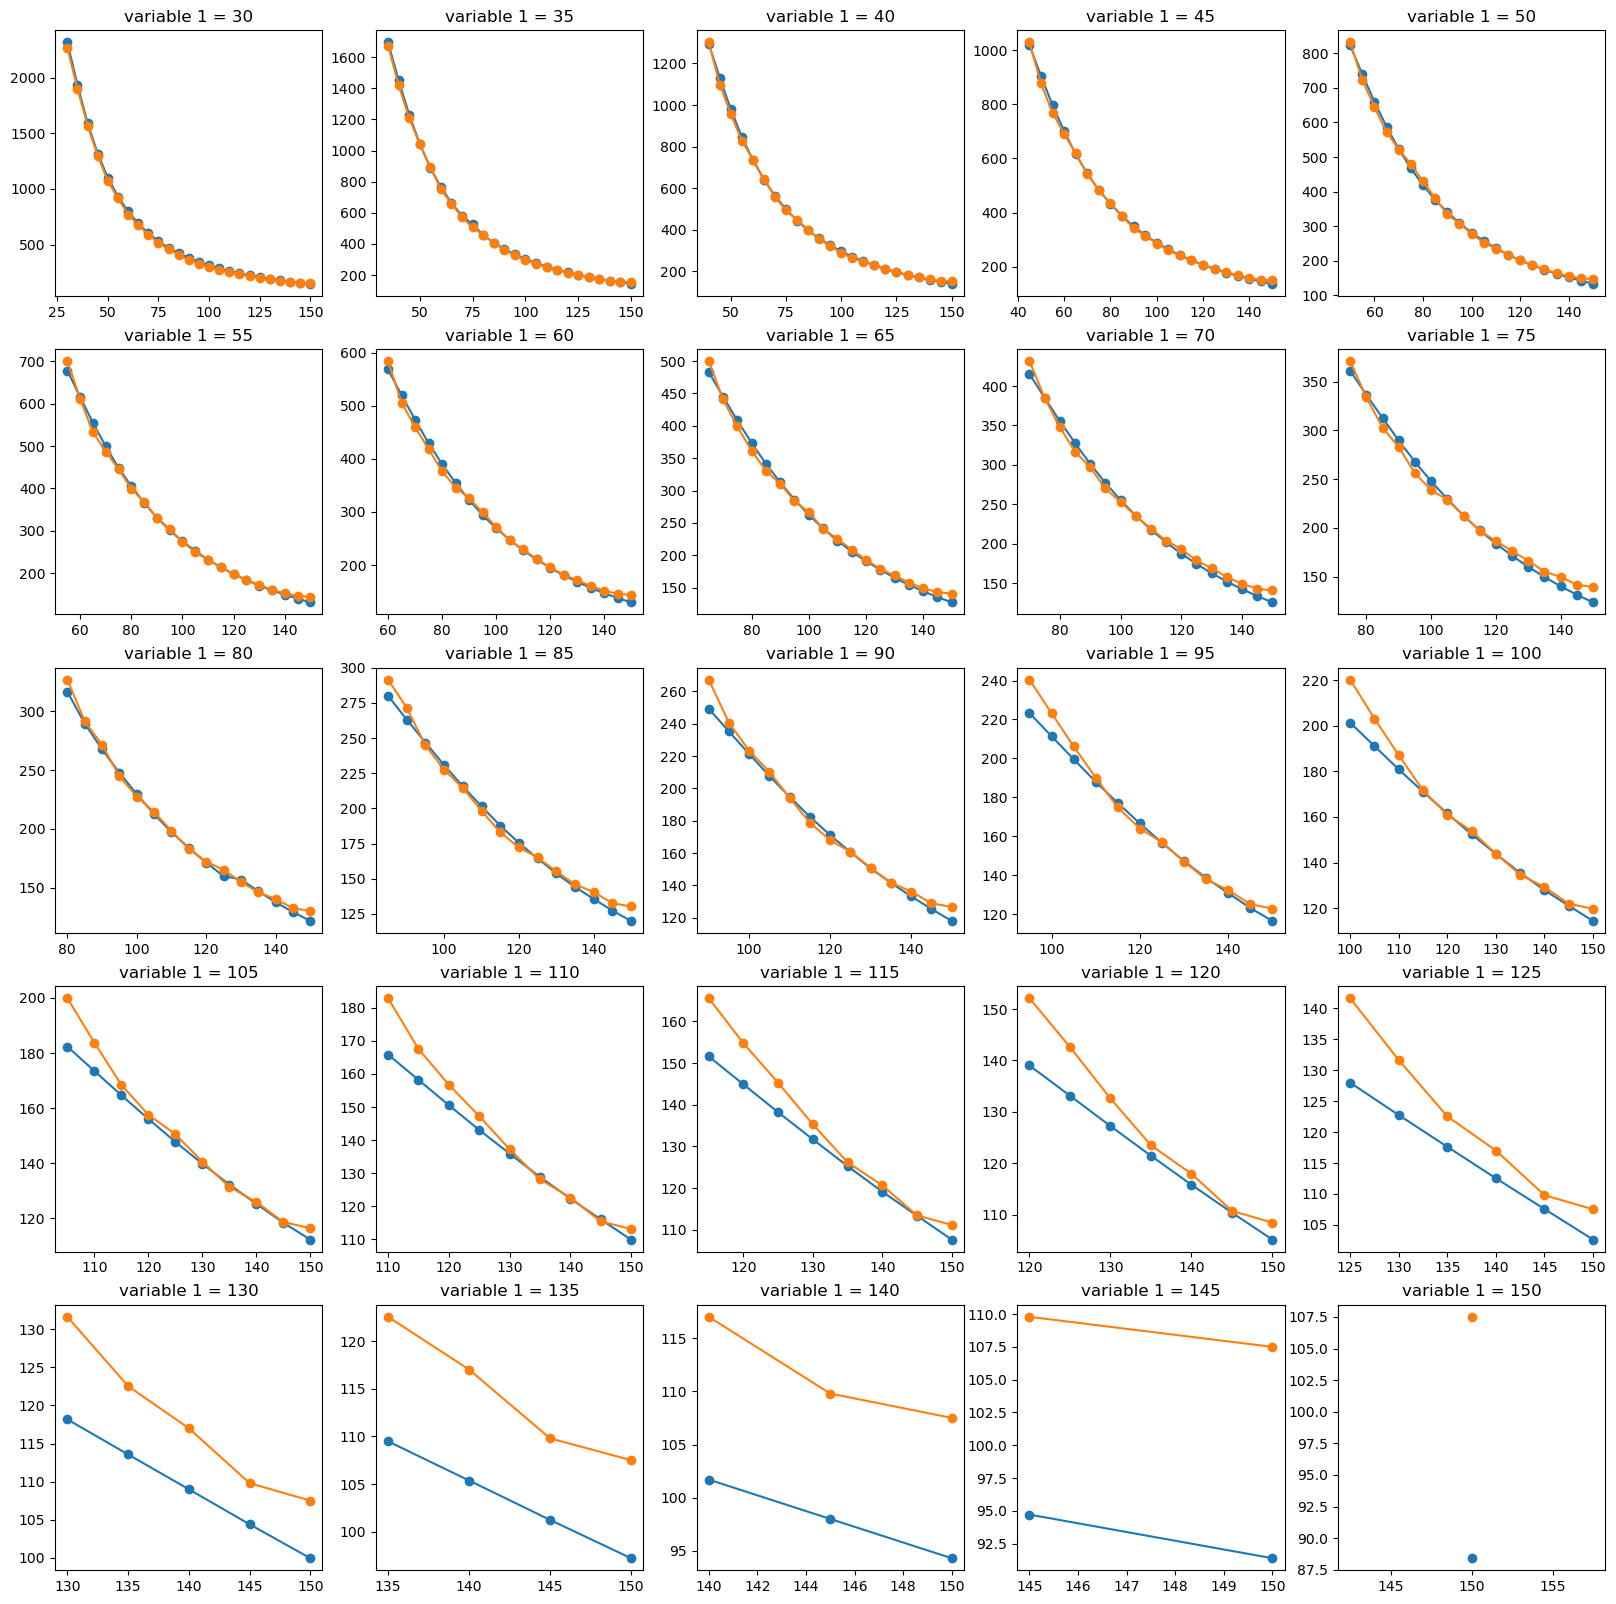

In [26]:
plot2d_var1const('GBR')

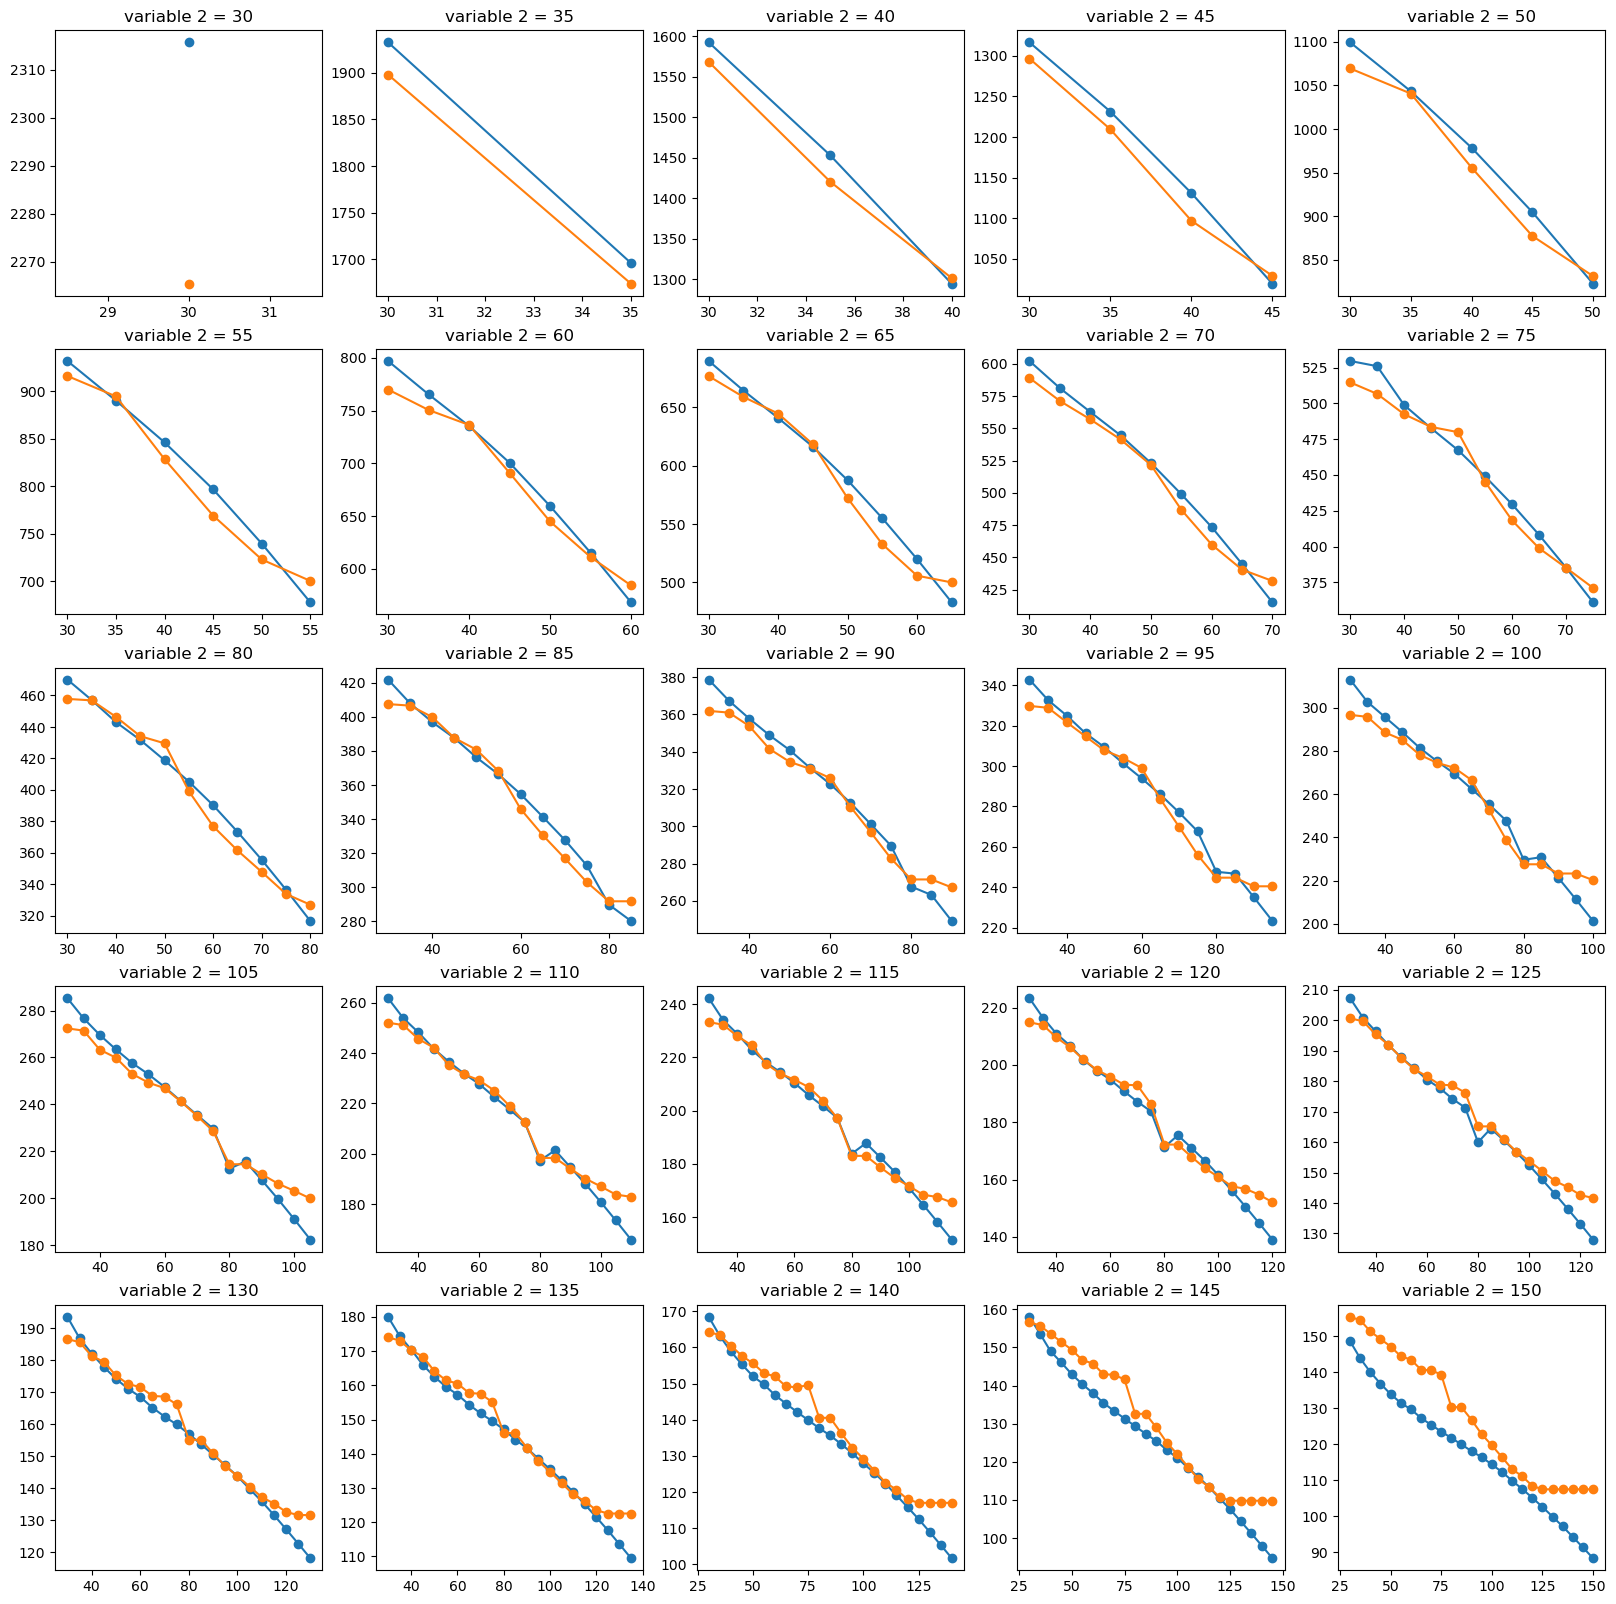

In [27]:
plot2d_var2const('GBR')

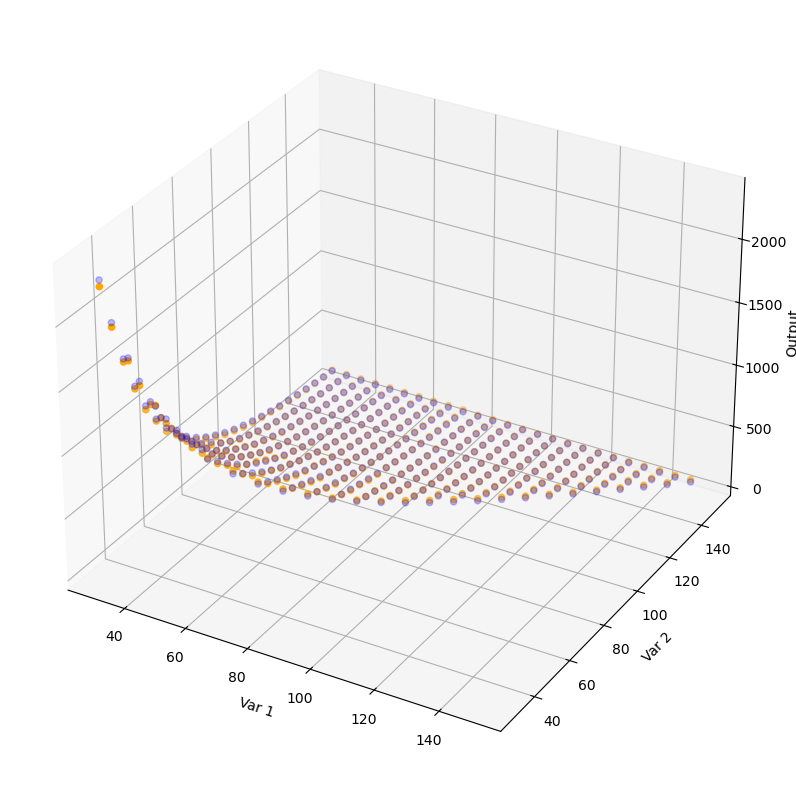

In [28]:
plot3d('GBR')

# AdaBoost Regressor

In [29]:
dtr = DecisionTreeRegressor(max_depth = 3)

ABR = AdaBoostRegressor(estimator = dtr,
                        n_estimators = 10,
                        learning_rate = 0.1,
                        loss = 'linear',
                        random_state = 0)

ABR.fit(X,Y)
df['ABR'] = ABR.predict(X)
print(mse(Y, df['ABR']))

1970.873634056997


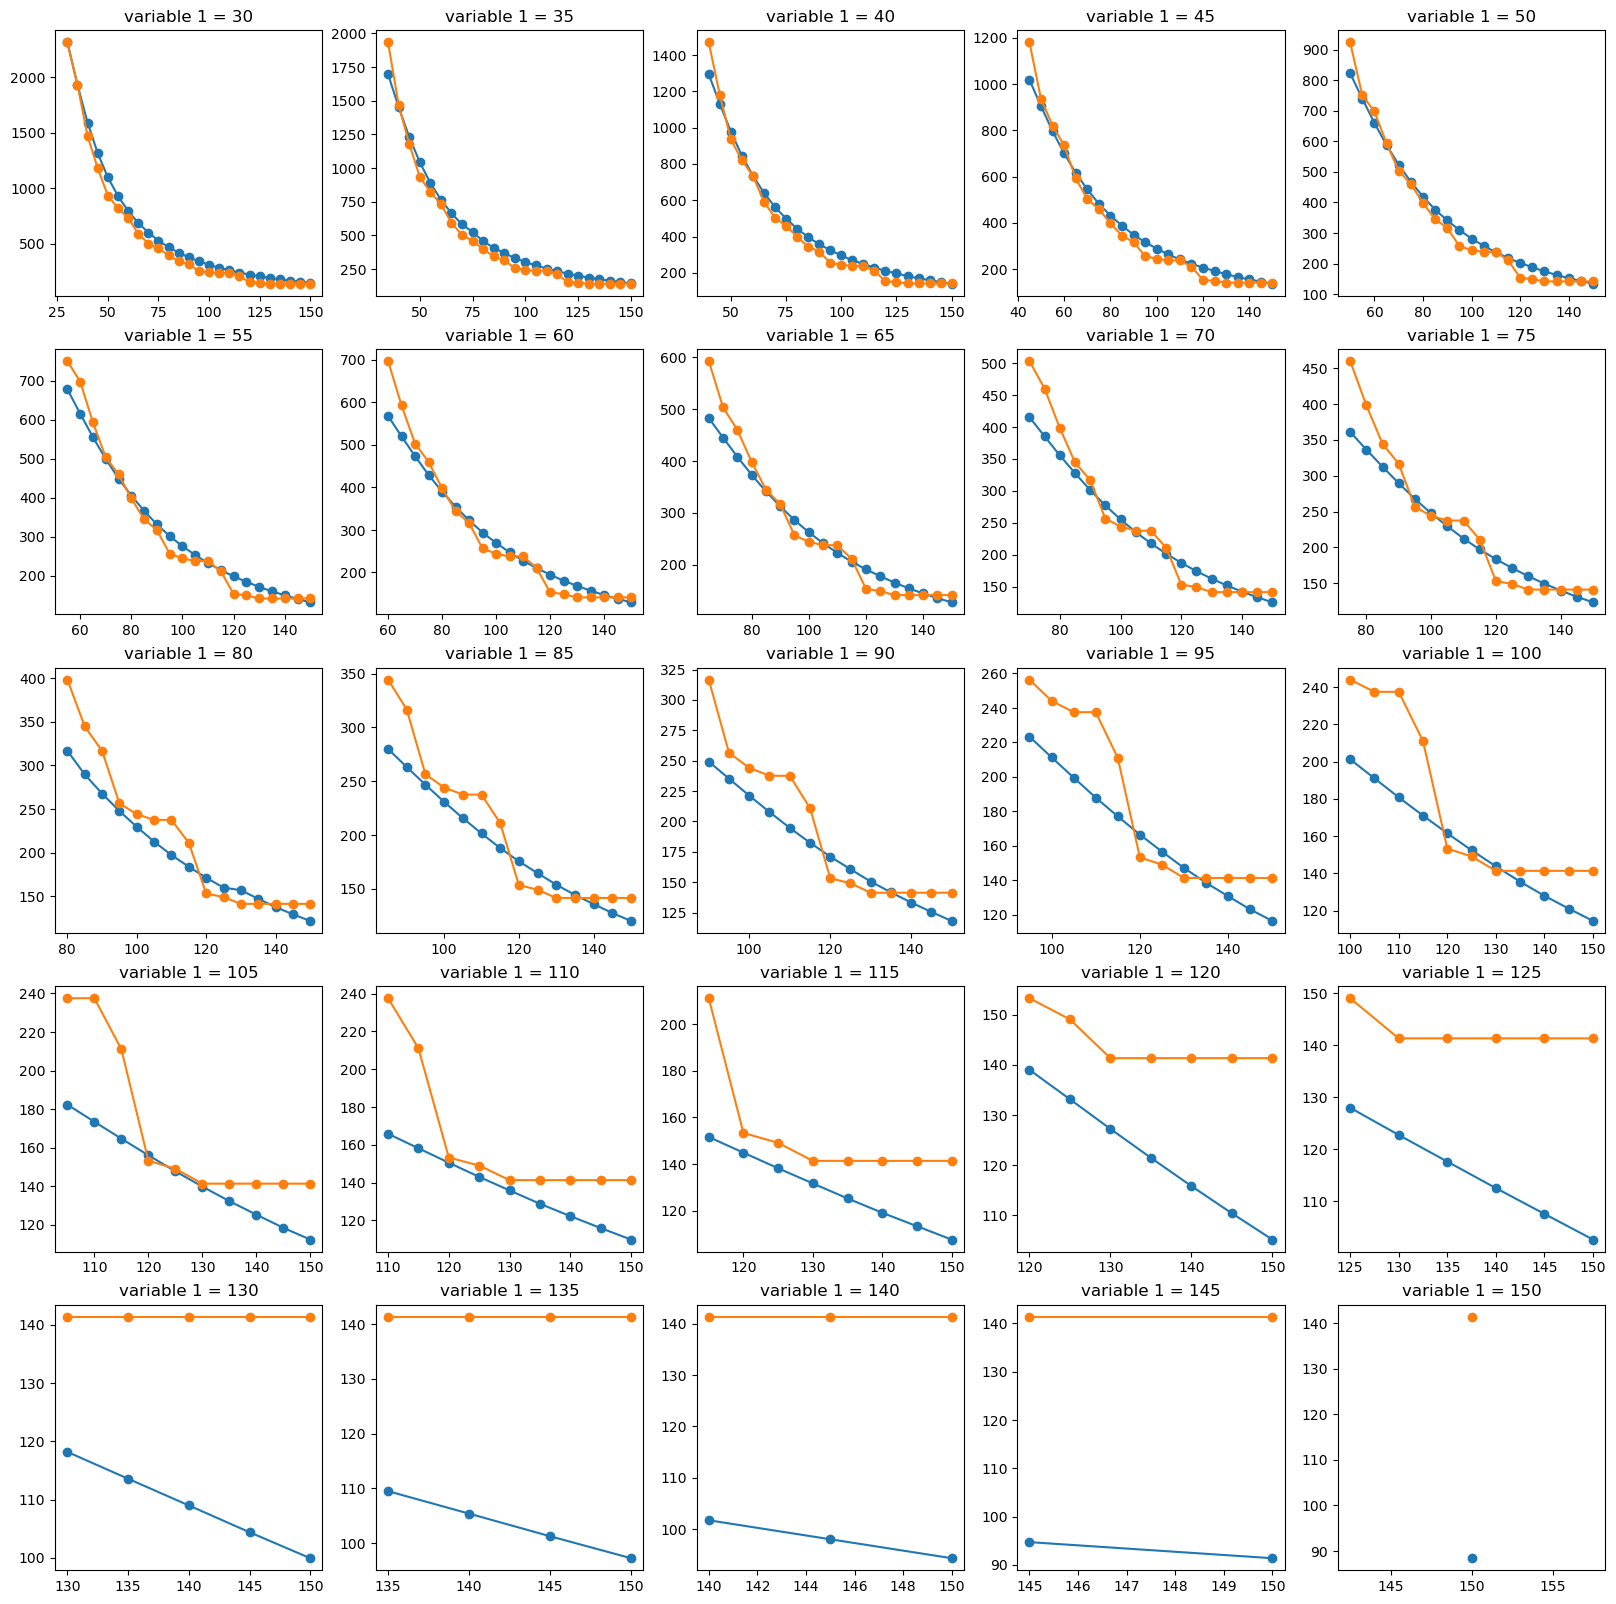

In [30]:
plot2d_var1const('ABR')

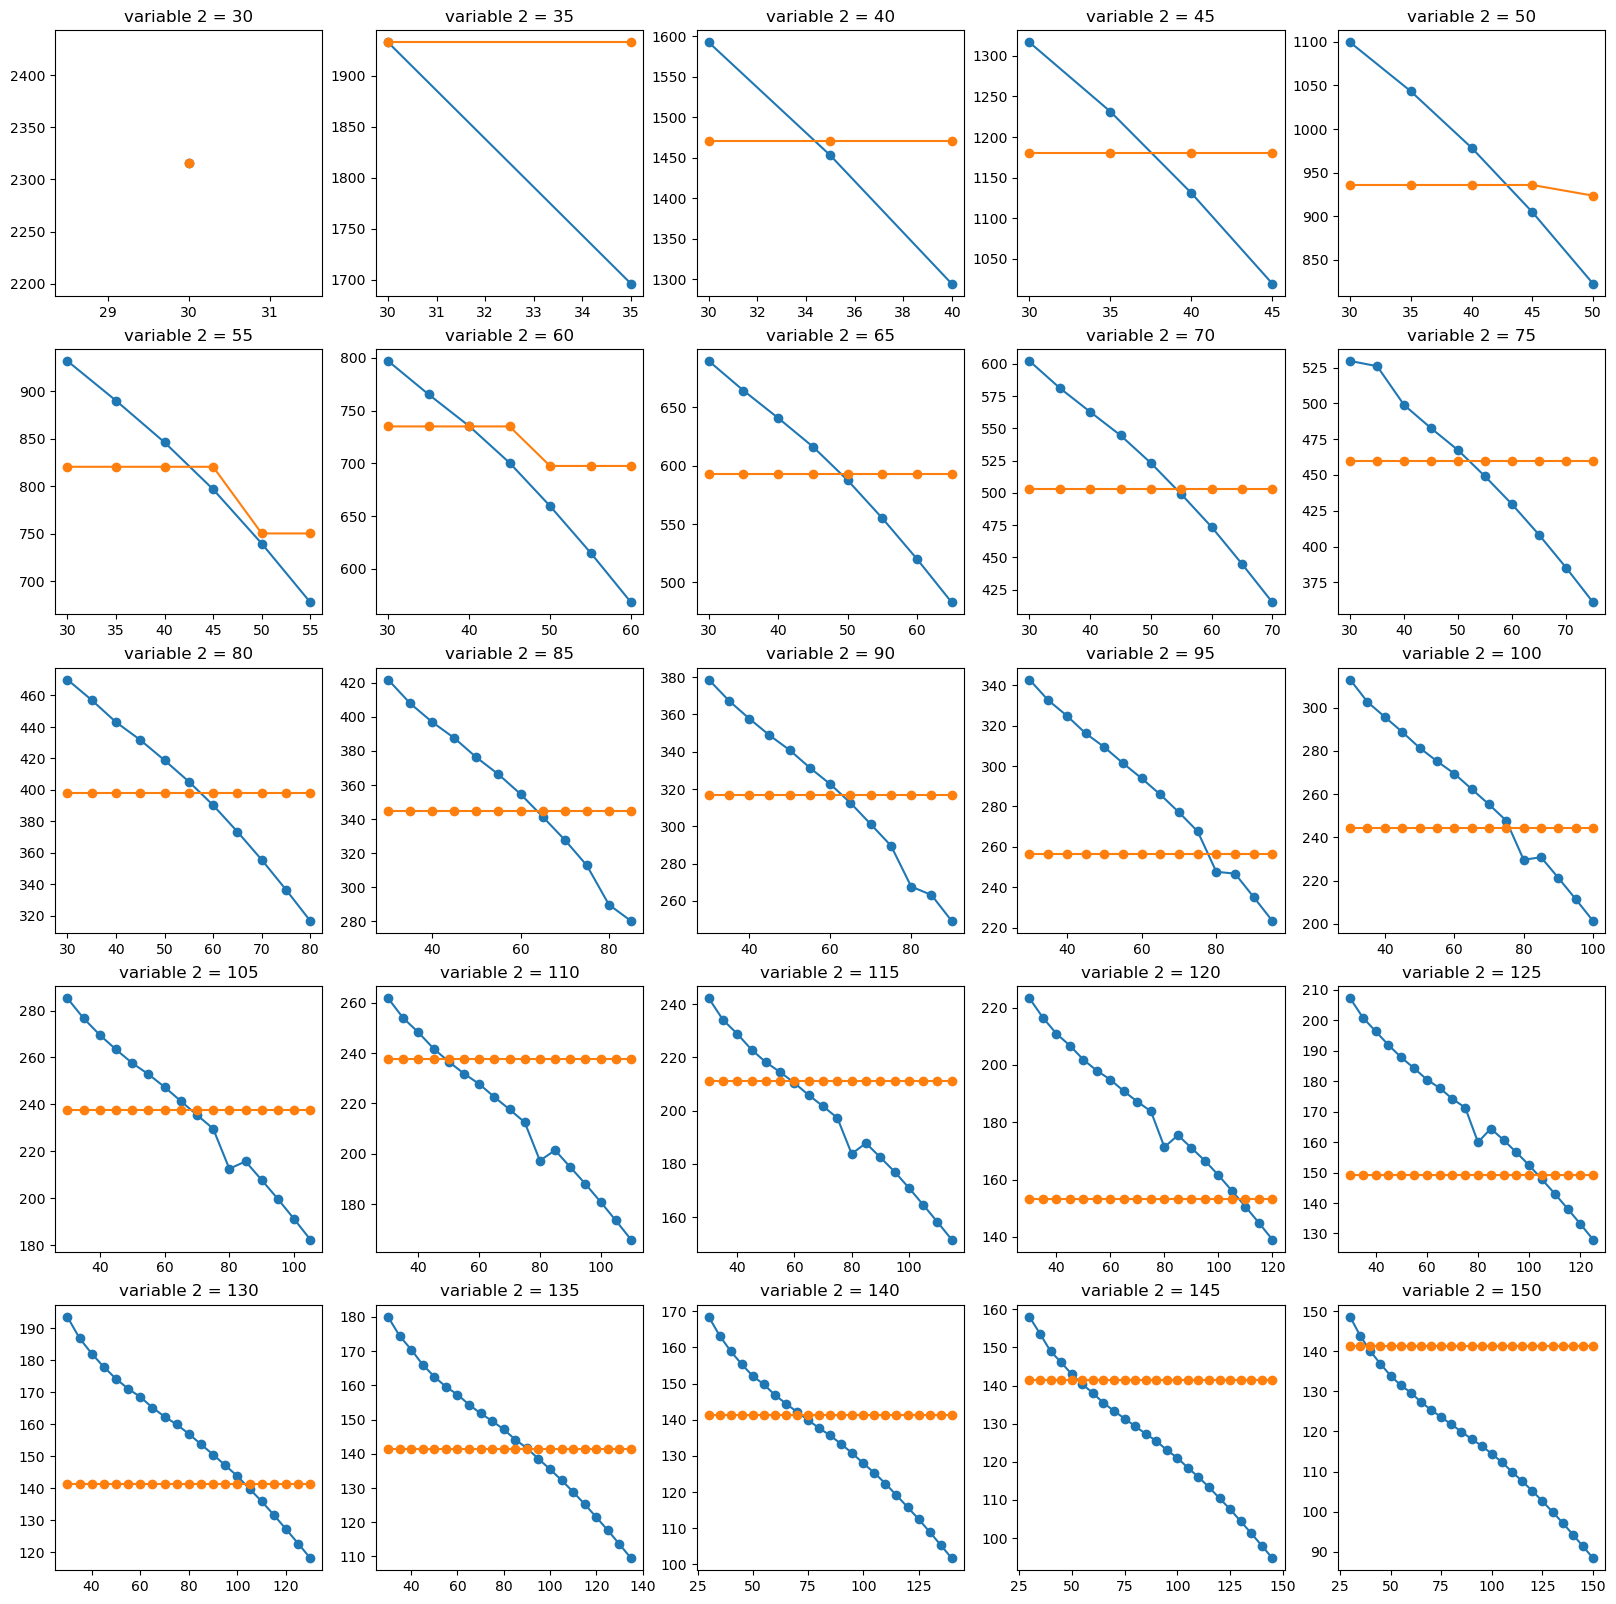

In [31]:
plot2d_var2const('ABR')

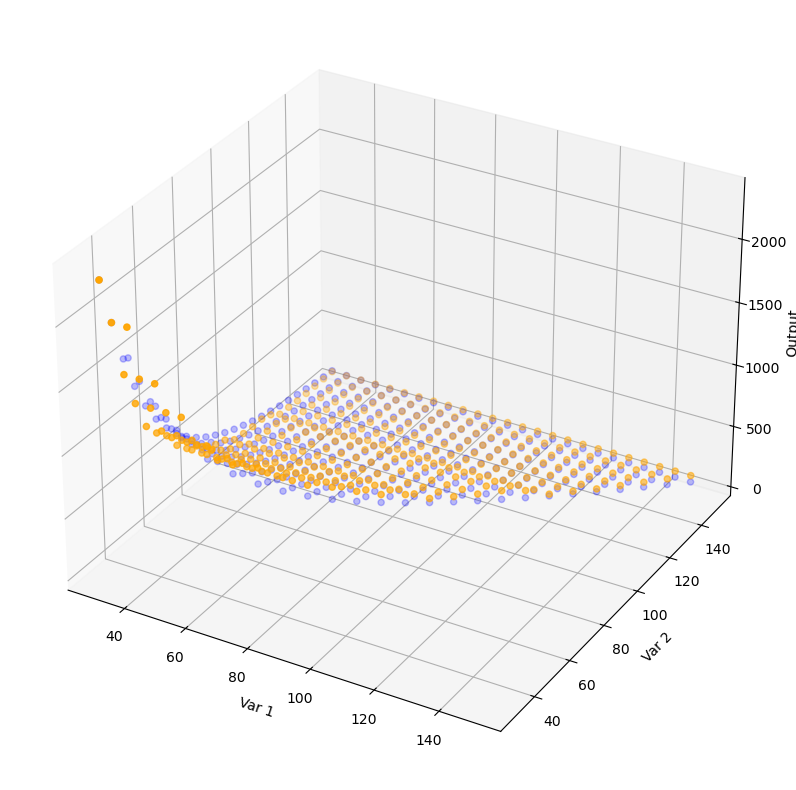

In [32]:
plot3d('ABR')

# XGBoost

In [33]:
XGB = xgboost.XGBRegressor(objective = 'reg:squarederror',
                        n_estimators = 10,
                        random_state = 0)

XGB.fit(X,Y)
df['XGB'] = XGB.predict(X)

print(mse(Y, df['XGB']))

677.190049978358


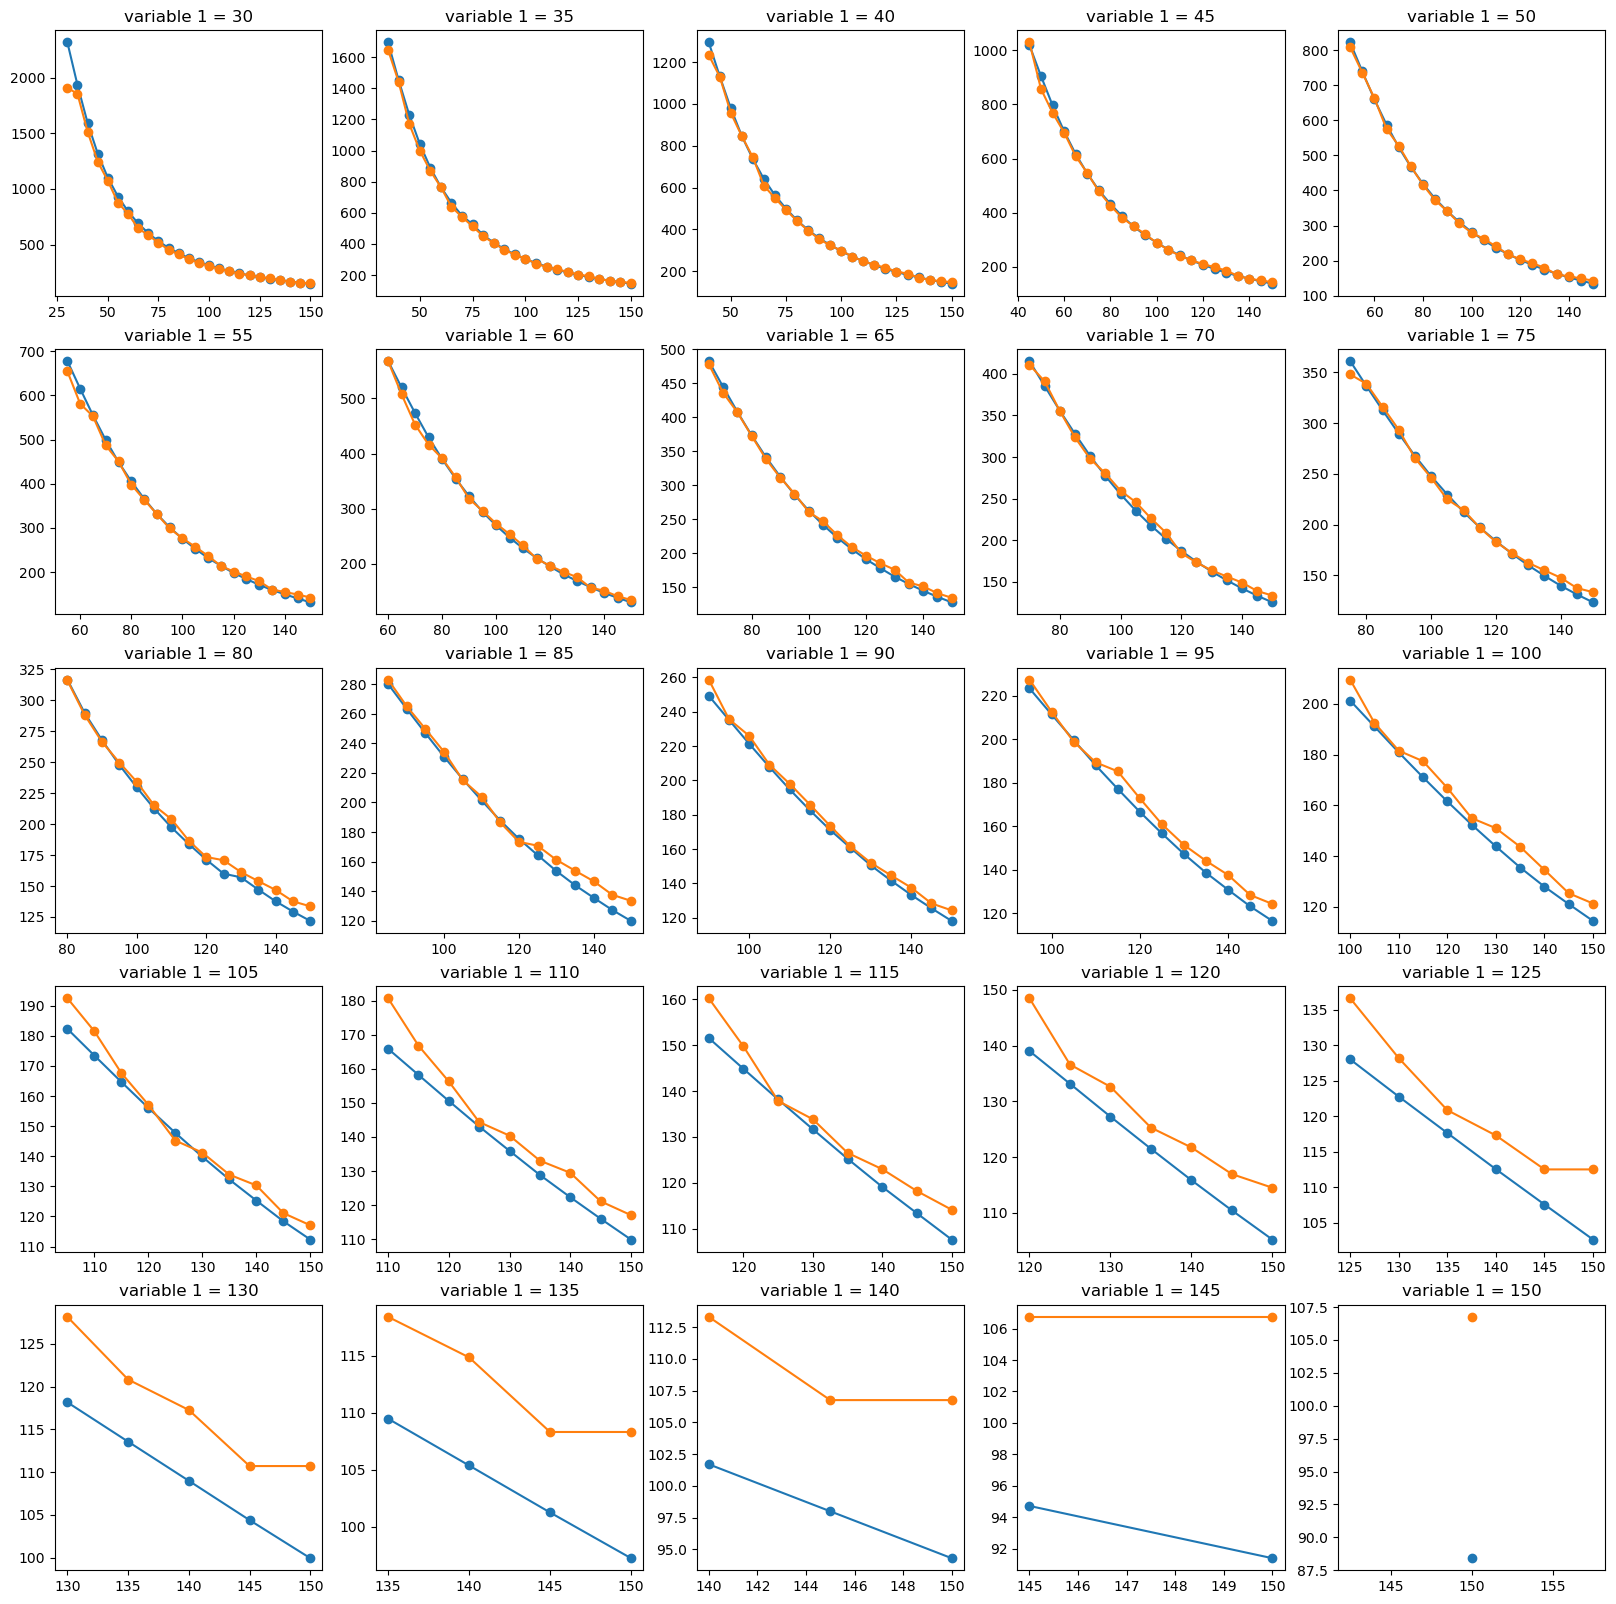

In [34]:
plot2d_var1const('XGB')

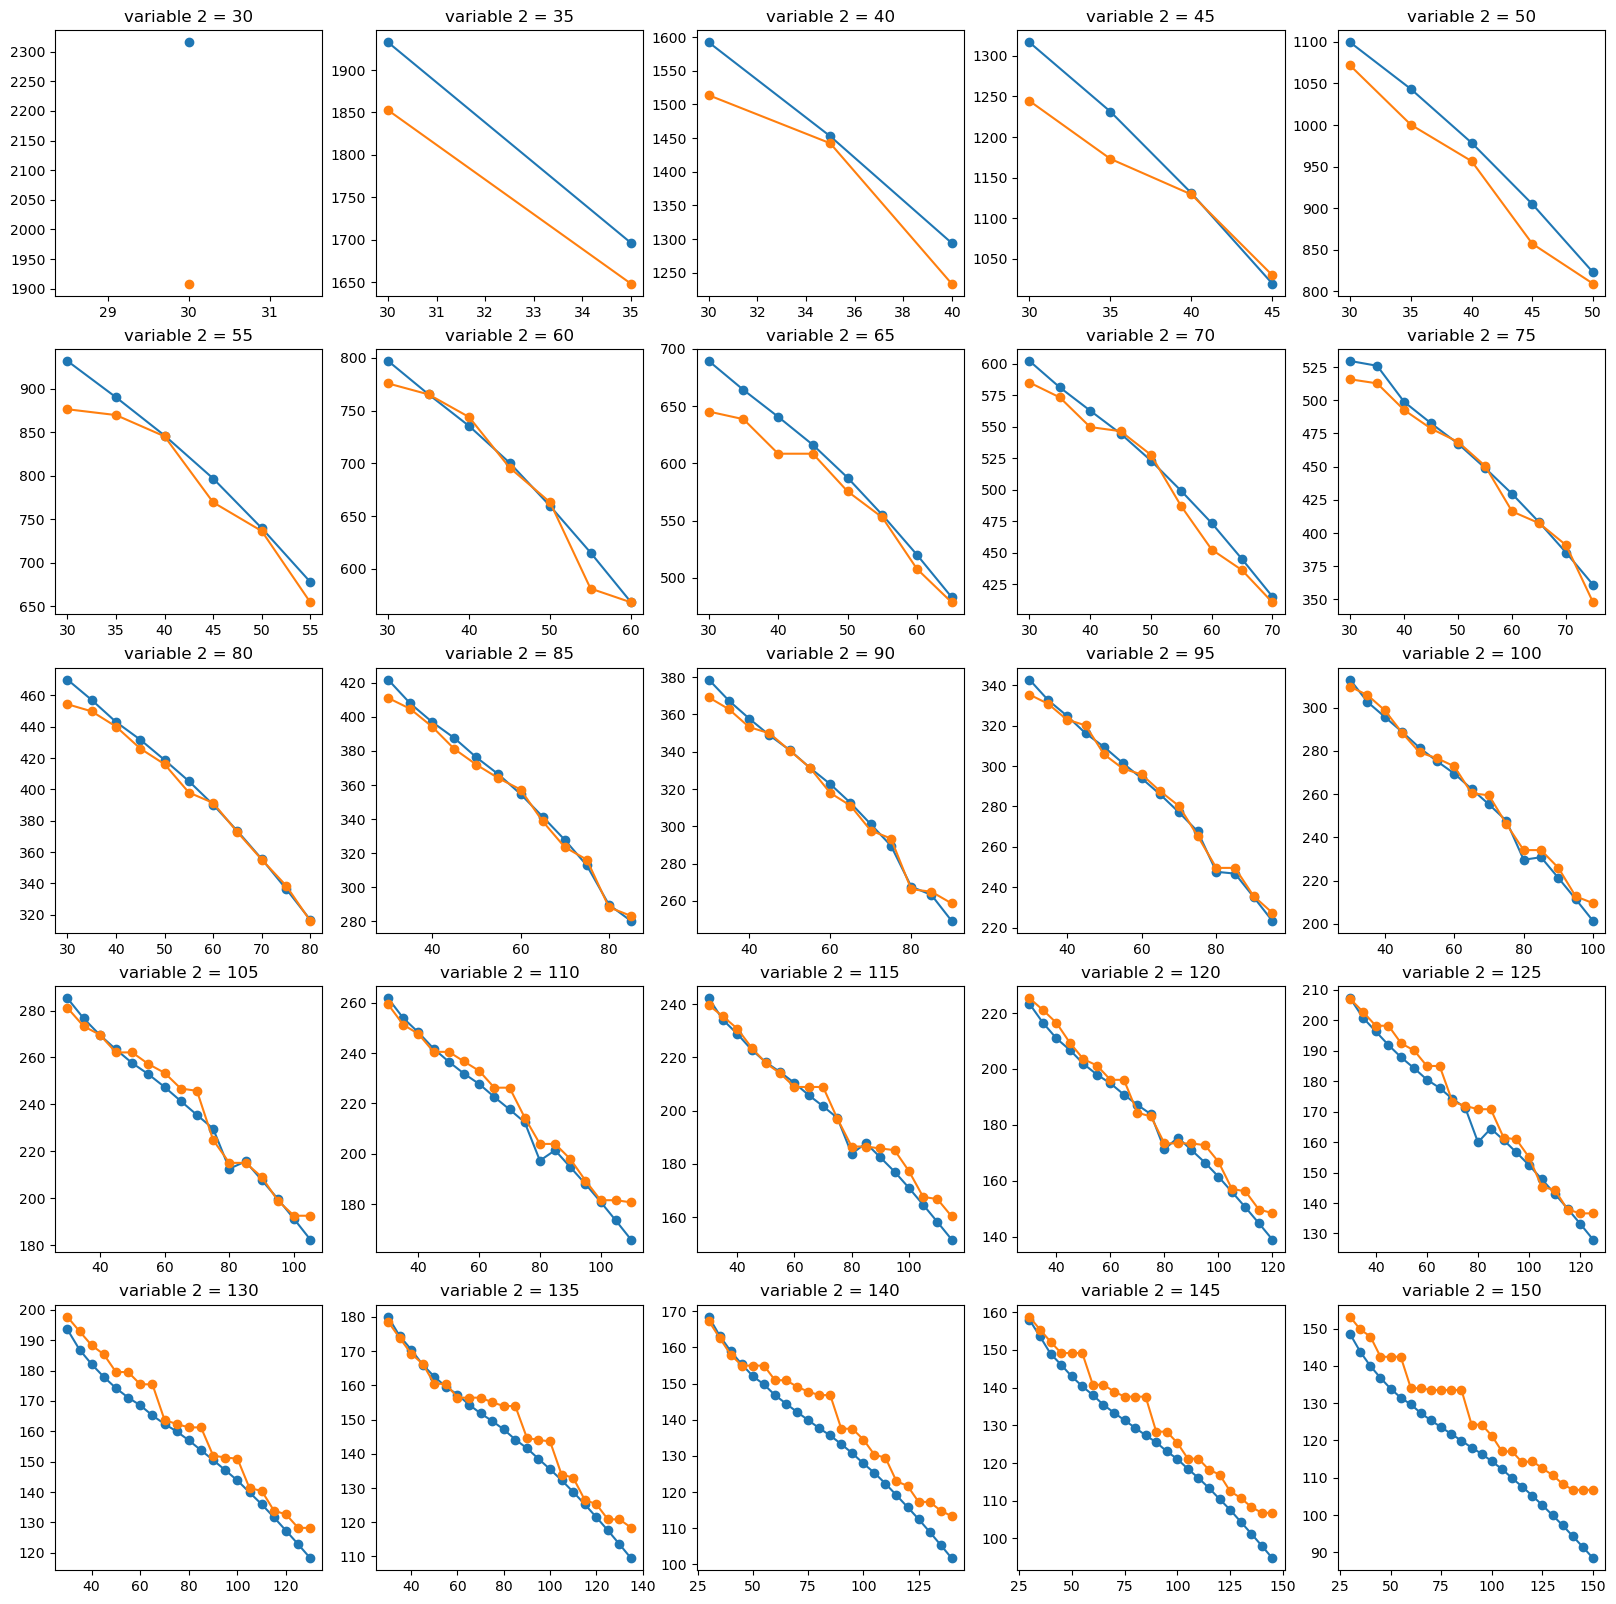

In [35]:
plot2d_var2const('XGB')

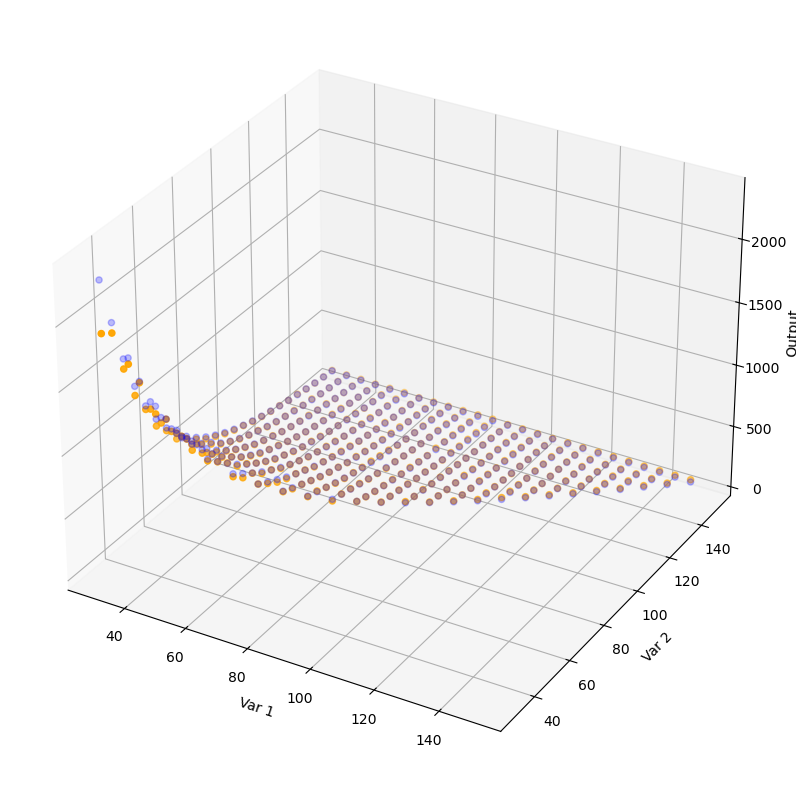

In [36]:
plot3d('XGB')

# LightGBM

In [37]:
LGBM = LGBMRegressor(metric = 'rmse')
LGBM.fit(X,Y)
df['LGBM'] = LGBM.predict(X)
print(mse(Y,df['LGBM']))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000022 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 48
[LightGBM] [Info] Number of data points in the train set: 325, number of used features: 2
[LightGBM] [Info] Start training from score 299.897862
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

c:\Users\rajee\miniconda3\envs\mlenv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


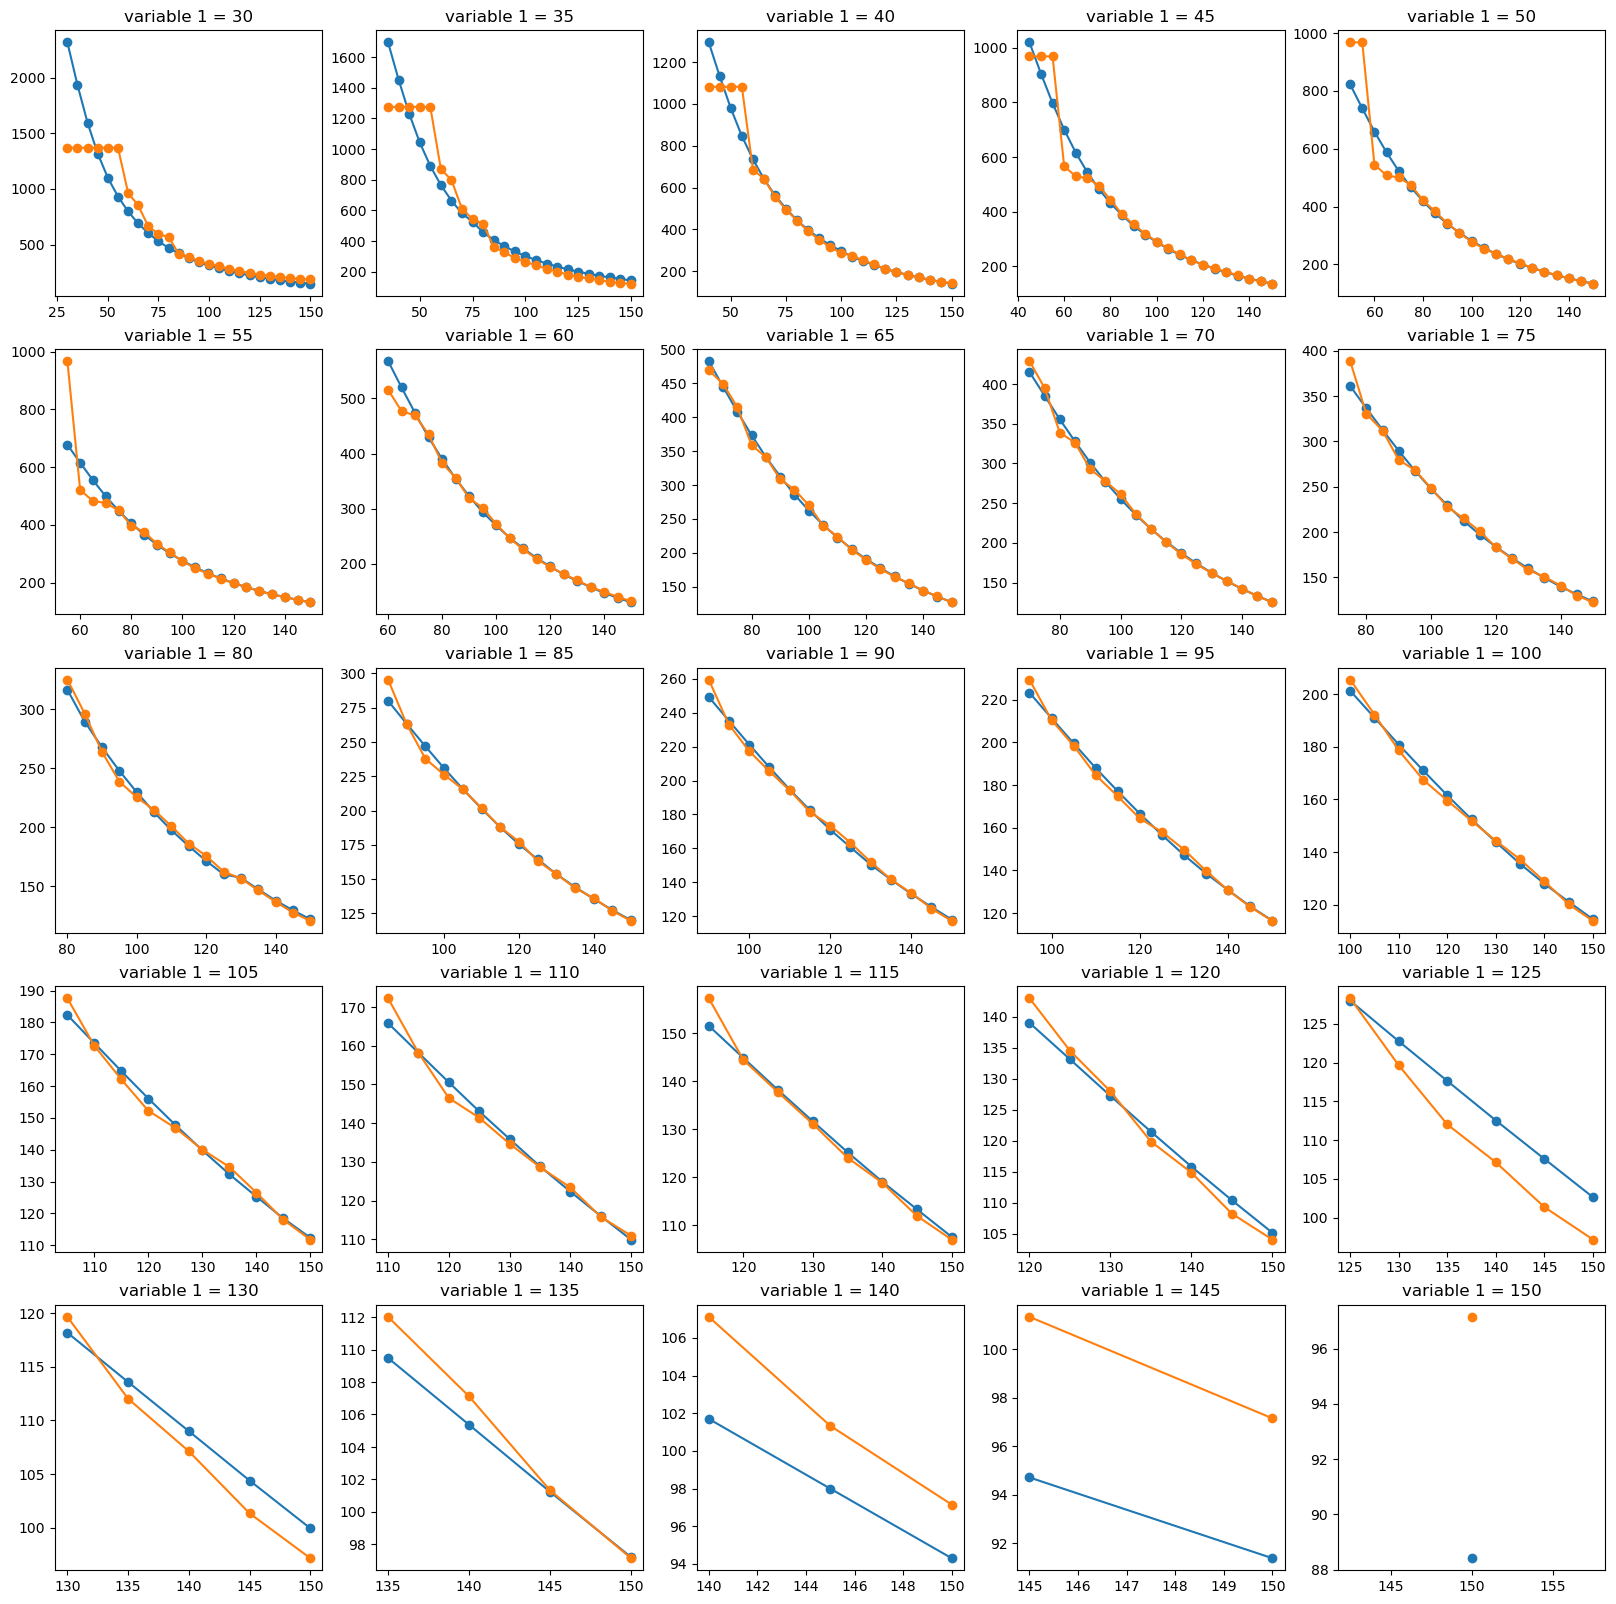

In [38]:
plot2d_var1const('LGBM')

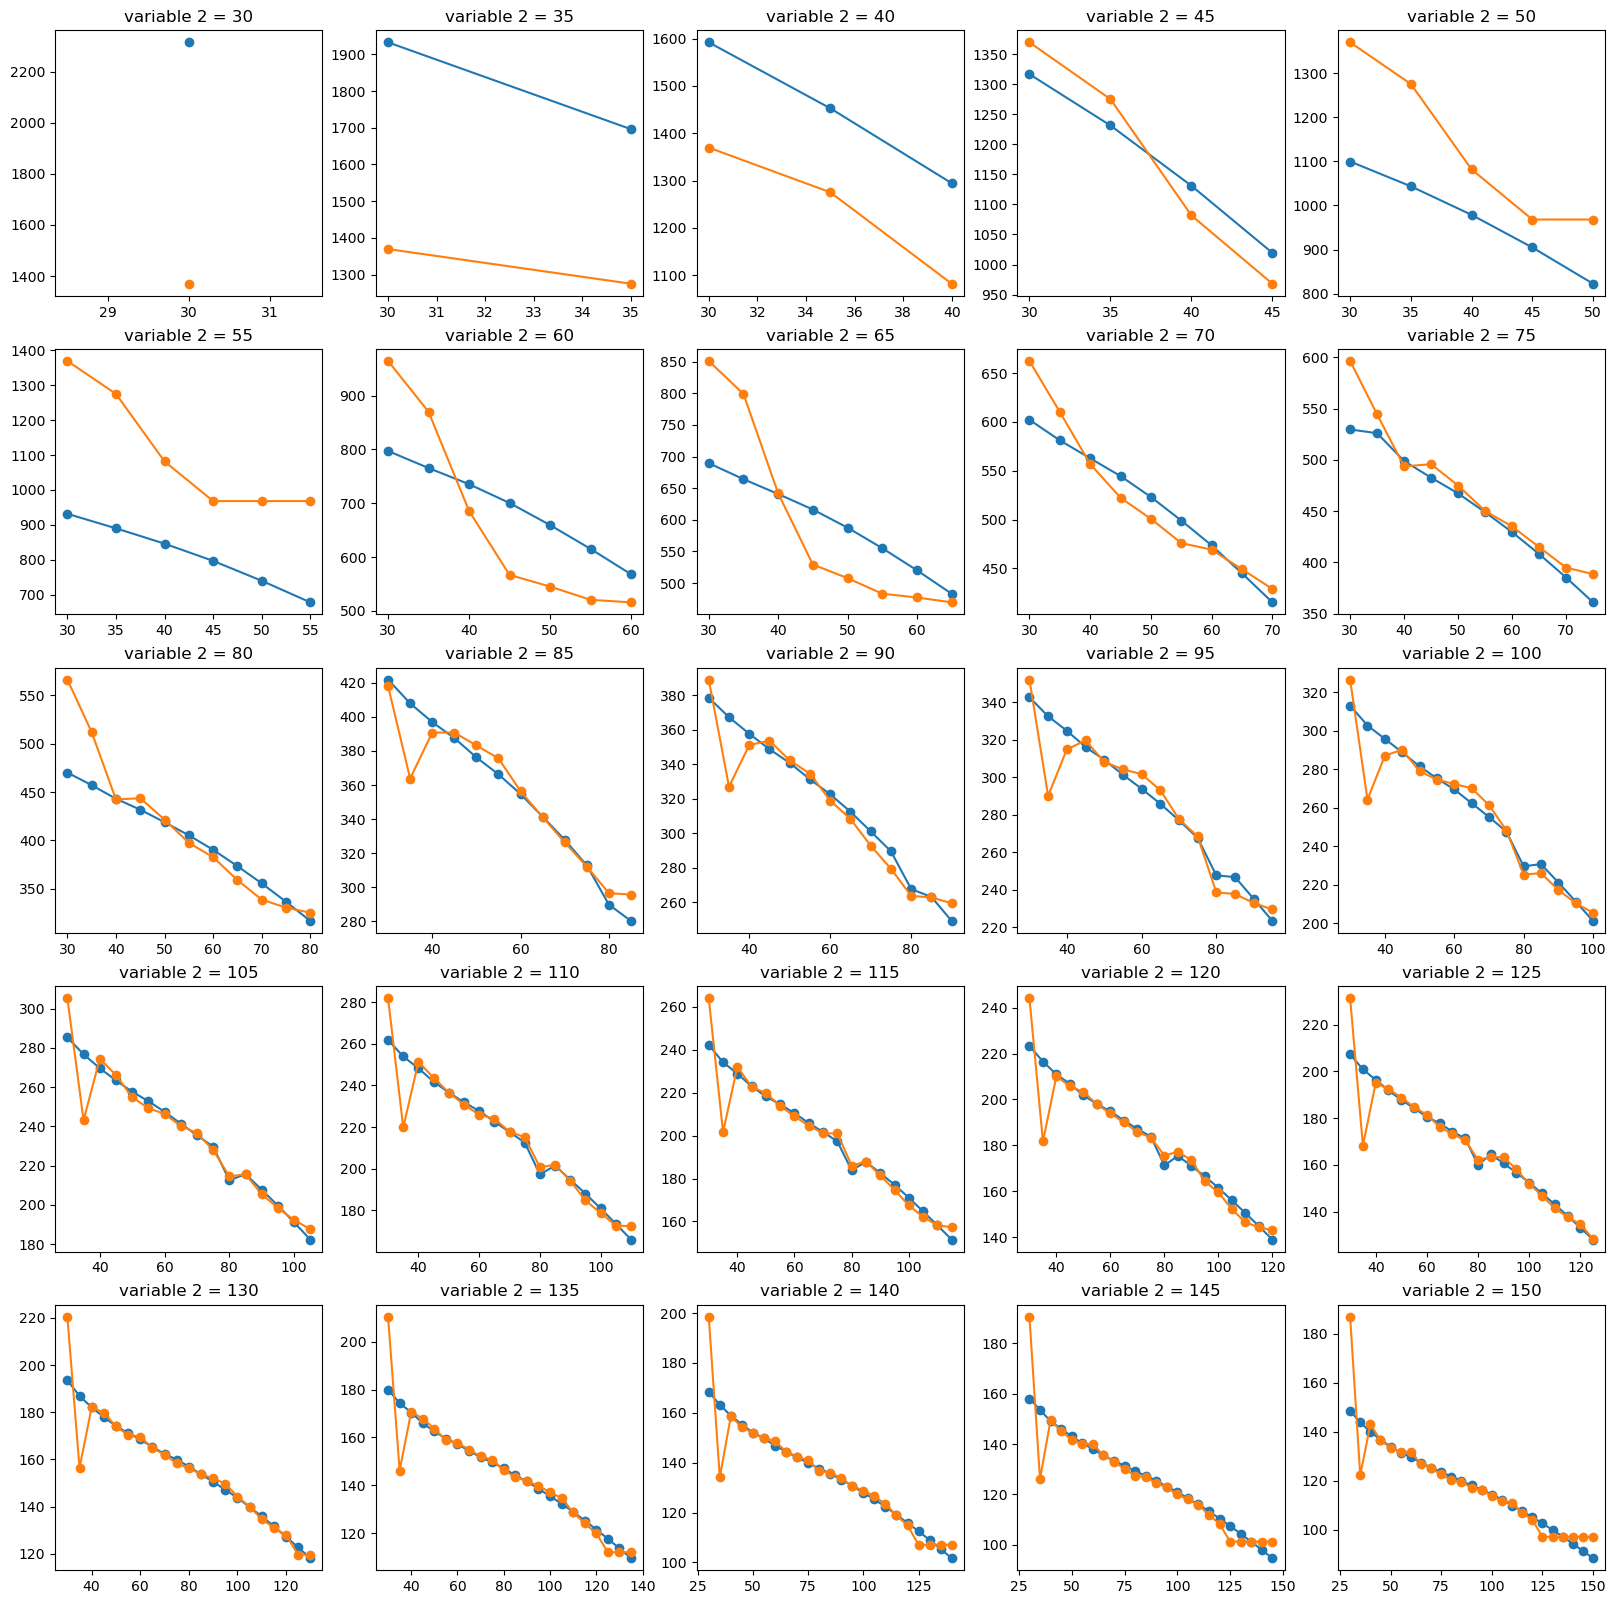

In [39]:
plot2d_var2const('LGBM')

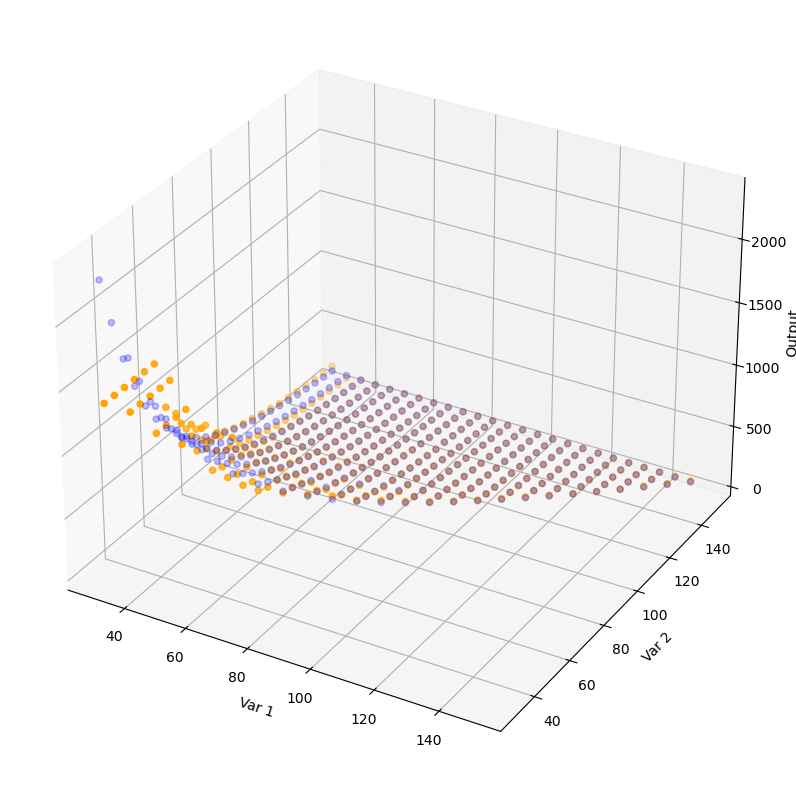

In [40]:
plot3d('LGBM')

# NN

In [41]:
scaler_Y = StandardScaler()
Y = scaler_Y.fit_transform(Y.values.reshape(-1,1))

In [42]:
NN = tf.keras.models.Sequential([
    tf.keras.layers.Dense(10, activation = 'relu', input_shape = (2,)),
    tf.keras.layers.Dense(10, activation = 'relu'),
    tf.keras.layers.Dense(1)
])

NN.compile(
    optimizer = 'adam',
    loss = 'mse',
    # metrics = ['mae']
)

history = NN.fit(X,Y, epochs = 5)

df['NN'] = scaler_Y.inverse_transform(NN.predict(X).reshape(-1,1))
print(mse(Y, df['NN']))

Epoch 1/5
11/11 [==============================] - 1s 2ms/step - loss: 1.5236
Epoch 2/5
11/11 [==============================] - 0s 2ms/step - loss: 1.2747
Epoch 3/5
11/11 [==============================] - 0s 2ms/step - loss: 1.0829
Epoch 4/5
11/11 [==============================] - 0s 2ms/step - loss: 0.9208
Epoch 5/5
11/11 [==============================] - 0s 1ms/step
237925.53660194884


In [43]:
NN.evaluate(X,Y)

11/11 [==============================] - 0s 2ms/step - loss: 0.7325


0.7324627041816711

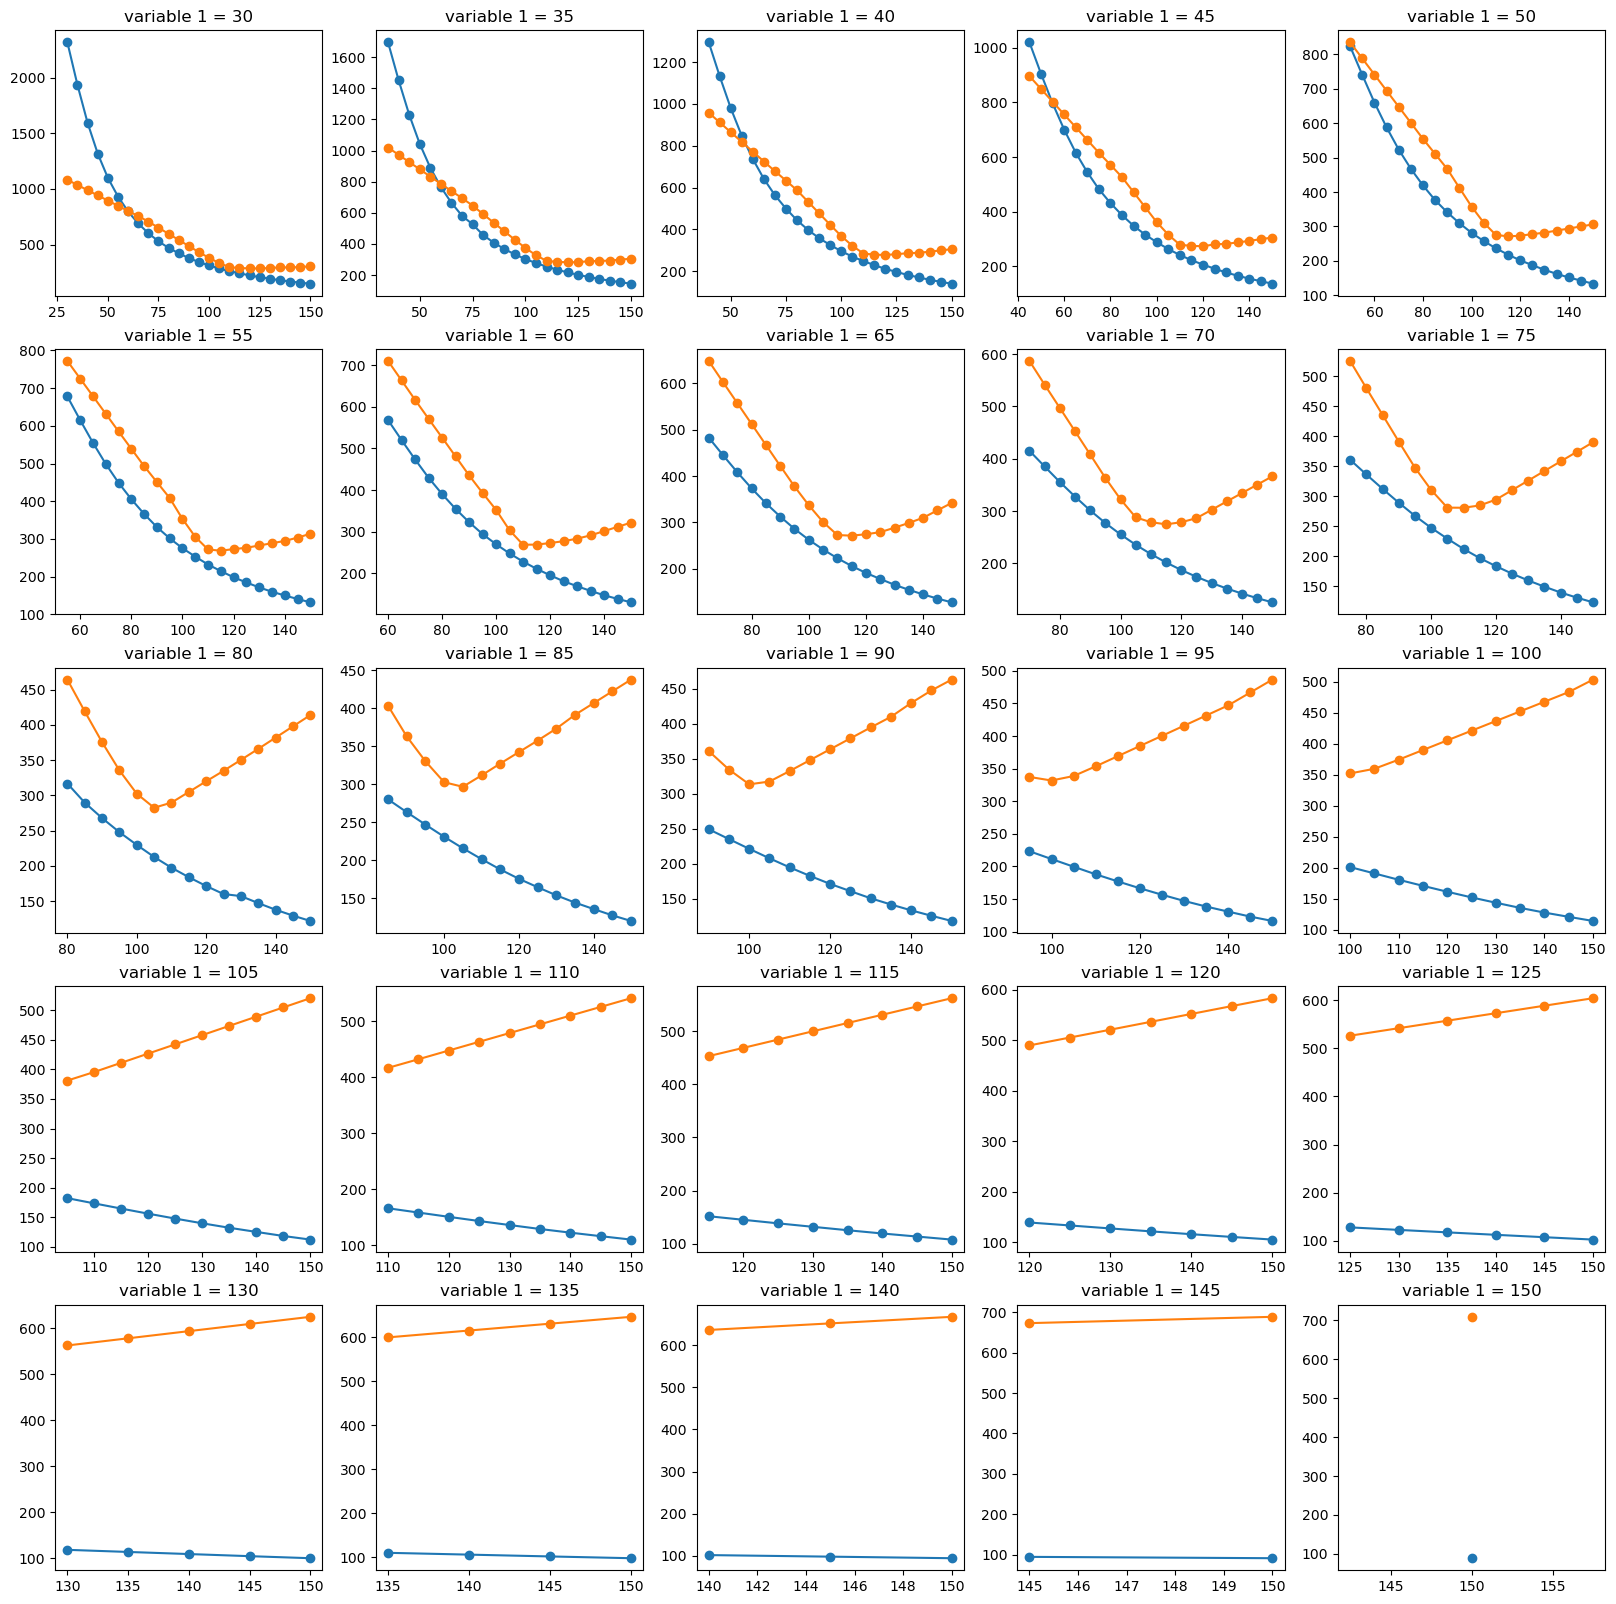

In [44]:
plot2d_var1const('NN')

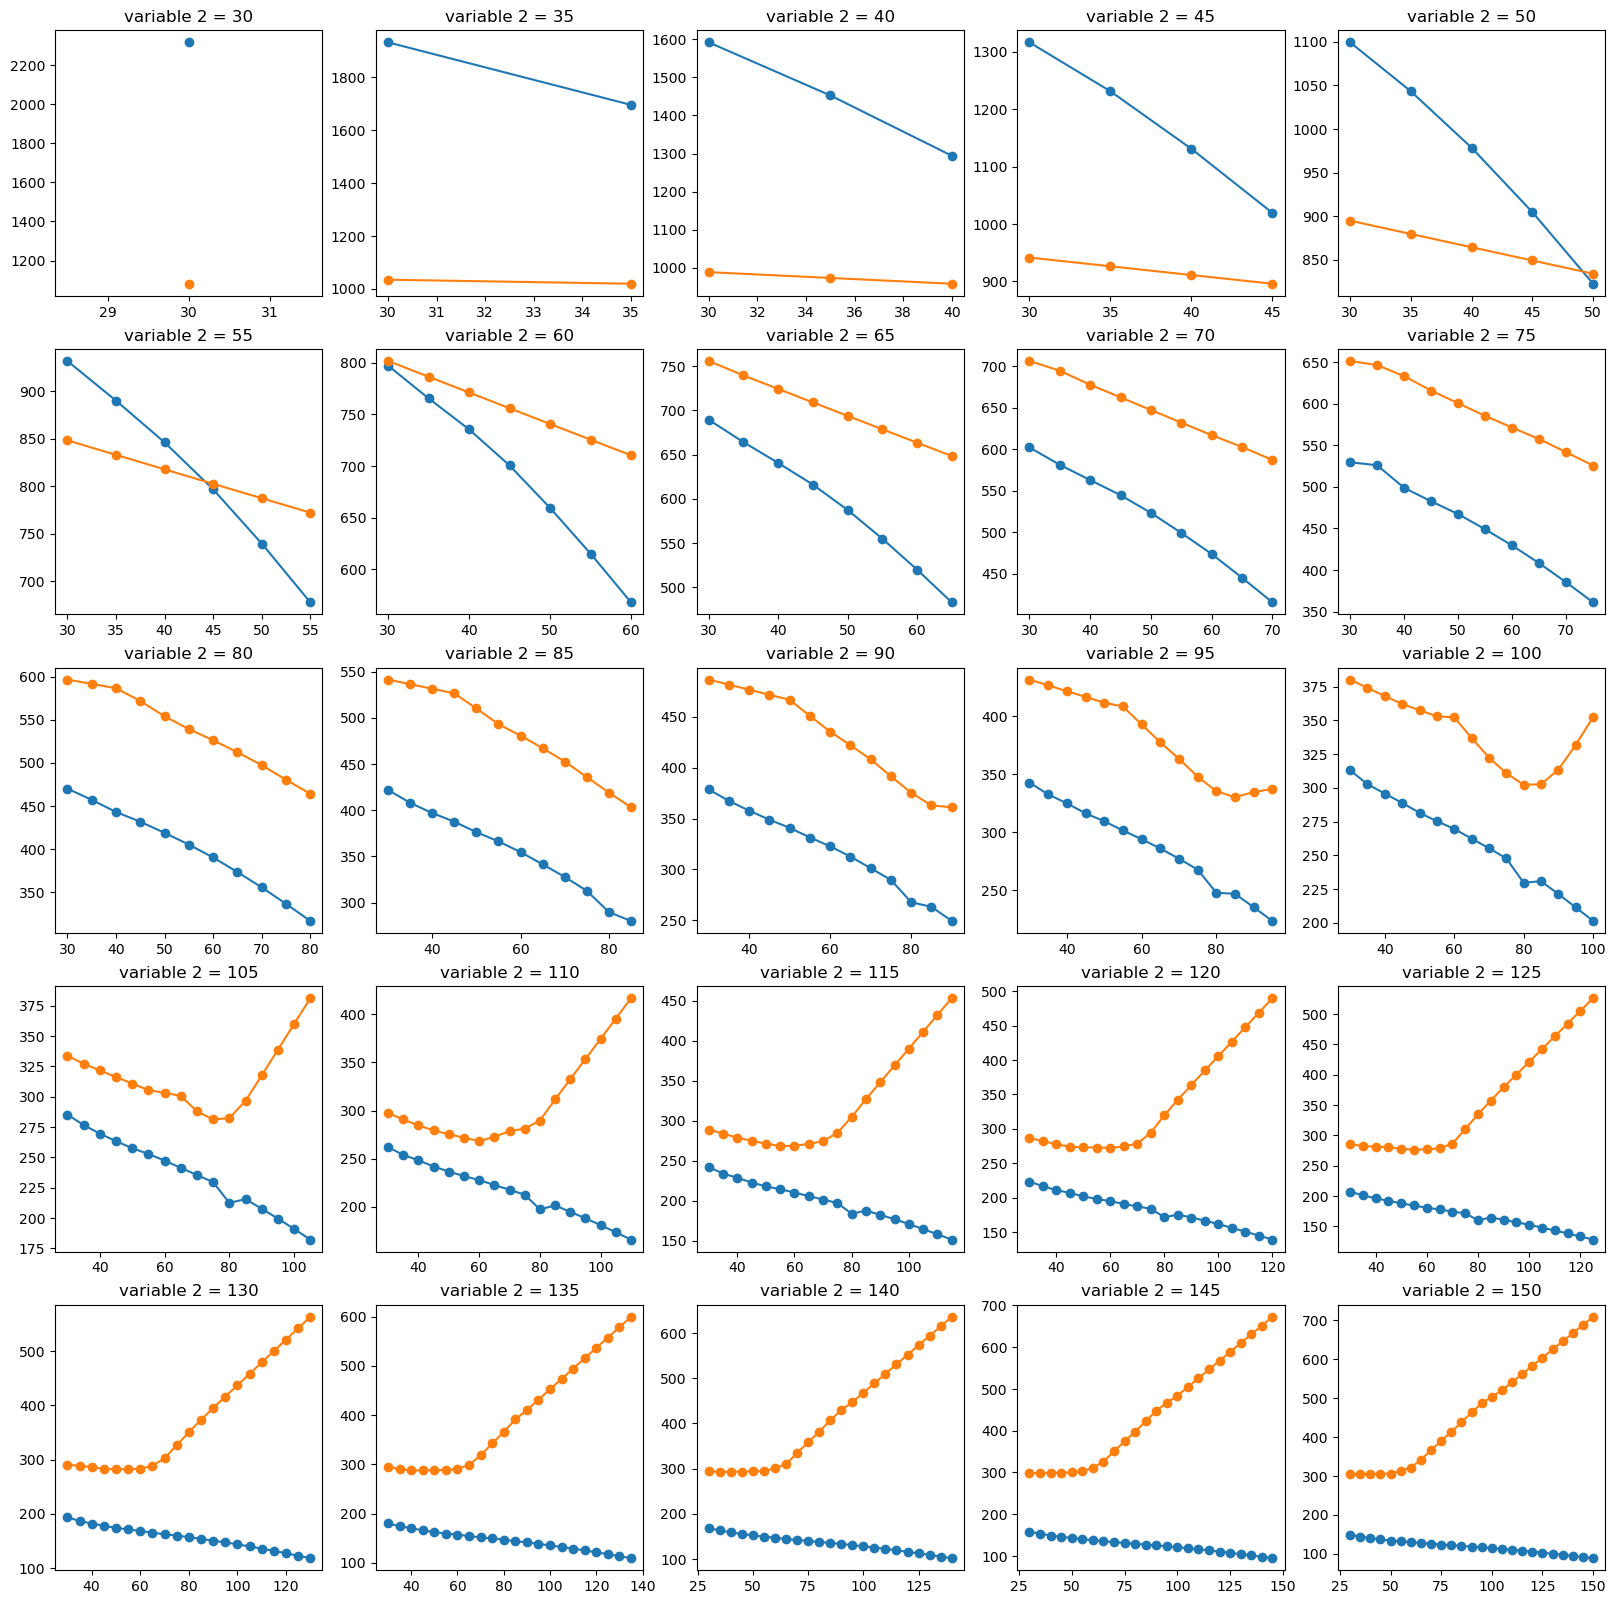

In [45]:
plot2d_var2const('NN')

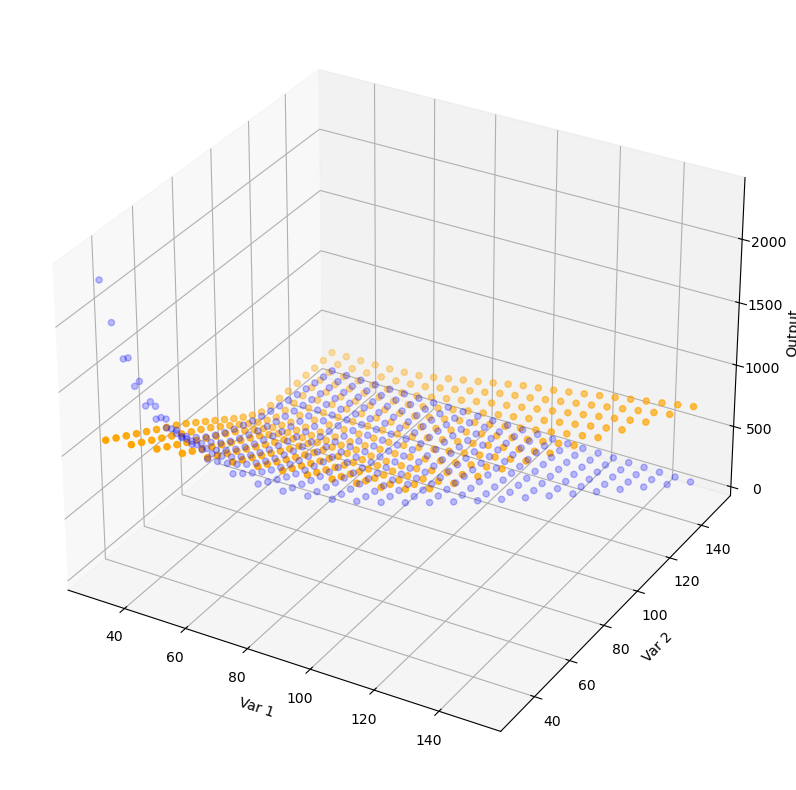

In [46]:
plot3d('NN')

In [47]:
df['Output'].values

array([2315.7  , 1932.6  , 1592.2  , 1316.6  , 1099.5  ,  931.63 ,
        797.07 ,  689.49 ,  602.12 ,  529.58 ,  470.11 ,  421.96 ,
        378.61 ,  342.78 ,  313.01 ,  285.26 ,  261.88 ,  242.24 ,
        223.3  ,  207.23 ,  193.55 ,  180.01 ,  168.44 ,  158.01 ,
        148.54 , 1696.1  , 1452.8  , 1231.3  , 1043.3  ,  889.97 ,
        765.4  ,  664.18 ,  581.15 ,  525.95 ,  457.11 ,  407.98 ,
        367.27 ,  332.6  ,  302.65 ,  276.7  ,  253.97 ,  234.07 ,
        216.5  ,  200.86 ,  186.89 ,  174.43 ,  163.17 ,  153.58 ,
        143.8  , 1294.3  , 1131.   ,  978.57 ,  846.07 ,  735.4  ,
        640.69 ,  562.72 ,  498.81 ,  443.08 ,  396.97 ,  357.7  ,
        324.93 ,  295.72 ,  269.6  ,  248.26 ,  228.84 ,  210.91 ,
        196.34 ,  182.08 ,  170.44 ,  158.89 ,  148.99 ,  139.98 ,
       1019.4  ,  904.73 ,  796.7  ,  700.53 ,  616.17 ,  544.54 ,
        482.61 ,  431.74 ,  387.57 ,  348.78 ,  316.23 ,  288.78 ,
        263.4  ,  241.83 ,  222.88 ,  206.75 ,  191.85 ,  177.

In [48]:
df['NN'].values

array([1081.5427 , 1034.8727 ,  988.2027 ,  941.53265,  894.86273,
        848.1927 ,  801.5227 ,  756.00134,  706.3701 ,  651.4257 ,
        596.4814 ,  541.53705,  486.5927 ,  431.64835,  380.22684,
        333.88477,  297.4886 ,  289.09534,  286.60492,  285.55417,
        289.7499 ,  295.39526,  294.77942,  298.3537 ,  304.3895 ,
       1019.6385 ,  972.9685 ,  926.29846,  879.62854,  832.95856,
        786.2885 ,  739.61847,  694.56396,  646.4453 ,  591.5009 ,
        536.5566 ,  481.61224,  426.66788,  374.0569 ,  327.09705,
        290.76352,  284.03268,  282.0439 ,  282.29306,  288.88623,
        290.032  ,  292.93164,  298.7842 ,  304.82   ,  957.7727 ,
        911.06433,  864.3942 ,  817.7243 ,  771.0543 ,  724.3843 ,
        677.7143 ,  633.12665,  586.52057,  531.5762 ,  476.6318 ,
        421.68744,  367.98026,  321.66586,  284.48297,  278.97003,
        277.4829 ,  281.42938,  285.85324,  287.89774,  293.1789 ,
        299.2147 ,  305.2505 ,  895.9083 ,  849.19696,  802.49

# All Results

In [49]:
df

,variable 1,variable 2,Output,custom,Linreg,DTReg,RFReg,GBR,ABR,XGB,LGBM,NN
0,30,30,2315.700,2275.556689,929.492625,2315.700000,2200.7700,2265.459092,2315.700000,1908.496094,1369.554931,1081.542725
1,30,35,1932.600,1878.507646,892.620457,1814.350000,2009.2200,1898.043524,1932.600000,1852.588379,1369.554931,1034.872681
2,30,40,1592.200,1561.149575,855.748288,1446.433333,1636.9900,1568.093904,1469.985714,1513.691650,1369.554931,988.202698
3,30,45,1316.600,1306.986275,818.876120,1133.378333,1276.3300,1296.628279,1180.877778,1244.475830,1369.554931,941.532654
4,30,50,1099.500,1102.936294,782.003951,1133.378333,1071.4730,1069.554477,935.830000,1071.644531,1369.554931,894.862732
...,...,...,...,...,...,...,...,...,...,...,...,...
320,140,145,97.999,96.875966,-27.577436,122.609127,98.3645,109.795820,141.344716,106.754135,101.333581,651.702515
321,140,150,94.303,88.224473,-64.449604,122.609127,95.2337,107.505190,141.344716,106.754135,97.150664,667.282288
322,145,145,94.712,94.593630,-32.532444,122.609127,95.3564,109.795820,141.344716,106.754135,101.333581,672.710876
323,145,150,91.383,86.182021,-69.404612,122.609127,92.0846,107.505190,141.344716,106.754135,97.150664,688.290649
